In [6]:
import pandas as pd
import numpy as np
import os
import torch
import seaborn as sns
import random
import math
import pickle
import matplotlib.gridspec as gridspec
from matplotlib.ticker import FuncFormatter, LogFormatterMathtext, NullFormatter
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

from scipy.stats import pearsonr, spearmanr
from scipy.stats import rankdata
from matplotlib import pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_auc_score, average_precision_score




from Bio import pairwise2
from Bio.Seq import Seq
from Bio.Align import substitution_matrices
from Bio import SeqIO

from random import sample

import sys
import os

notebook_dir = os.getcwd()
code_dir = os.path.abspath(os.path.join(notebook_dir, '..', 'code'))
if code_dir not in sys.path:
    sys.path.append(code_dir)

from utils_for_analysis import (
    calculate_ss_for_df_and_factors,
    load_df_all,
    load_df_with_budget,
    discretized_parameter_scale,
    xlabel_dict,
    ylabel_dict,
    title_fontsize,
    label_fontsize,
    tick_fontsize,
    legend_fontsize,
    original_parameter_scale,
    color_map,
    fix_ticks,
    get_labels,
    positions,
    num_muts_column_name,
    DATASET_PATHS,
    plot_exporter
)


In [7]:
export_plot = plot_exporter("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/epistasis_analyses", style_axes=True)

In [8]:

def get_relevant_columns_gfp_protgym(df, first_col, last_col):
    si = np.where(df.columns == first_col)[0][0]
    ei = np.where(df.columns == last_col)[0][0]+1
    return df.columns[si:ei]

def nmt_relevant_columns(df):
    si = np.where(df.columns == "1")[0][0]
    ei = np.where(df.columns == "272")[0][0]+1
    positions_with_mutations =  np.array([len(pd.unique(df.iloc[:,i])) > 1 for i in range(si,ei)])
    return df.columns[si:ei][positions_with_mutations]

def get_relevant_columns(dataset, df):
    cols = get_relevant_columns_gfp_protgym(df, positions[dataset][0], positions[dataset][1])
    return cols



# --- OHE Feature Creation ---
def get_one_hot_encoding(sdf, relevant_columns):
    one_hot_encoding = pd.get_dummies(sdf[relevant_columns])
    return one_hot_encoding

datasets_and_activity = {
    "gcn4": {"path": "./data/gcn4/gcn4.csv", "activity_col": "activity"},
    "pard3": {"path": "./data/pard3/pard3.csv", "activity_col": "activity"},
    "pte": {"path": "./data/pte/pte.csv", "activity_col": "p-nitrophenyl_octanoate"},
    "nmt": {"path": "./data/nmt/nmt_full_seq.csv", "activity_col": "activity"},
    "lov": {"path": "./data/lov/lov.csv", "activity_col": "activity"},
    "gfp": {"path": "./data/gfp/gfp_dataset_10mut.csv", "activity_col": "inactive"},
    "aamyl": {"path": "./data/aamyl/aamyl.csv", "activity_col": "activity"},
    "trpb": {"path": "./data/trpb/trpb.csv", "activity_col": "activity"},
    "nucb": {"path": "./data/nucb/nucb.csv", "activity_col": "activity"},
    "ired": {"path": "./data/ired/ired.csv", "activity_col": "activity"},
    "his2": {"path": "./data/his2/his2.csv", "activity_col": "activity"},
    "his5": {"path": "./data/his5/his5.csv", "activity_col": "activity"},
    "casp": {"path": "./data/casp/casp.csv", "activity_col": "activity"}
}





In [9]:
def plot_gof_fraction_panels(
    dataset_order, nrows=2, ncols=None, figsize=None, text_size=6,
    max_mutations=11, percentile=0.5, bar_width=0.25, bar_gap=0.10,
    collision_padding=1.08, wspace=0.12, hspace=0.22,
    show_positive_fraction=True
):
    n_datasets = len(dataset_order)

    if n_datasets == 0:
        raise ValueError("dataset_order is empty.")

    nrows = min(nrows, n_datasets)

    if ncols is None:
        ncols = int(np.ceil(n_datasets / nrows))

    if nrows * ncols < n_datasets:
        raise ValueError("nrows * ncols is smaller than the number of datasets.")

    if figsize is None:
        figsize = (3.2 * ncols, 2.8 * nrows)

    summaries = {}
    global_maximum = 0

    for dataset in dataset_order:
        df = pd.read_csv(DATASET_PATHS[dataset])

        mutation_column = (
            "num_muts" if "num_muts" in df.columns else num_muts_column_name[dataset]
        )

        df[mutation_column] = pd.to_numeric(df[mutation_column], errors="coerce")
        df = df.dropna(subset=[mutation_column]).copy()
        df[mutation_column] = np.rint(df[mutation_column]).astype(int)
        df = df[df[mutation_column] <= max_mutations].copy()

        nmuts = df[mutation_column].to_numpy()

        if dataset == "gfp":
            gof = (1 - df["inactive"]).to_numpy(dtype=int)
        else:
            activity_column = datasets_and_activity[dataset]["activity_col"]
            activity = df[activity_column].to_numpy(dtype=float)
            gof = (activity > np.quantile(activity, percentile)).astype(int)

        summary = (
            pd.DataFrame({"nmut": nmuts, "gof": gof})
            .groupby("nmut")["gof"]
            .agg(gof_fraction="mean", count="size")
            .sort_index()
        )

        summary["nmut_fraction"] = summary["count"] / len(df)
        summary["log10_count"] = np.log10(summary["count"].clip(lower=1))
        summaries[dataset] = summary

        if show_positive_fraction:
            global_maximum = max(
                global_maximum,
                summary["gof_fraction"].max(),
                summary["nmut_fraction"].max()
            )
        else:
            global_maximum = max(
                global_maximum,
                summary["log10_count"].max()
            )

    fig, axes_array = plt.subplots(
        nrows, ncols, figsize=figsize, sharex=False, sharey=True, squeeze=False
    )

    axes = axes_array.ravel()
    bar_offset = (bar_width + bar_gap) / 2
    annotation_groups = []

    y_axis_maximum = global_maximum * 1.15 if global_maximum > 0 else 1

    for panel_i, (ax, dataset) in enumerate(zip(axes, dataset_order)):
        summary = summaries[dataset]
        x = summary.index.to_numpy(dtype=int)
        column = panel_i % ncols

        if show_positive_fraction:
            gof_bars = ax.bar(
                x - bar_offset,
                summary["gof_fraction"],
                width=bar_width,
                color="steelblue"
            )

            nmut_bars = ax.bar(
                x + bar_offset,
                summary["nmut_fraction"],
                width=bar_width,
                color="darkorange"
            )

            fraction_annotations = ax.bar_label(
                gof_bars,
                labels=[
                    f"{value:.2f}"
                    for value in summary["gof_fraction"]
                ],
                padding=2,
                fontsize=text_size
            )

            count_annotations = ax.bar_label(
                nmut_bars,
                labels=[
                    f"N={count}"
                    for count in summary["count"]
                ],
                padding=2,
                rotation=90,
                fontsize=text_size
            )

            annotation_groups.append(
                (fraction_annotations, count_annotations)
            )

        else:
            count_bars = ax.bar(
                x,
                summary["log10_count"],
                width=bar_width,
                color="darkorange"
            )

            ax.bar_label(
                count_bars,
                labels=[
                    f"N={count}"
                    for count in summary["count"]
                ],
                padding=2,
                rotation=90,
                fontsize=text_size
            )

        ax.set_title(dataset, fontsize=text_size, pad=3)
        ax.set_ylim(0, y_axis_maximum)
        ax.set_xticks(x)
        ax.set_xticklabels([str(value) for value in x])

        ax.tick_params(
            axis="x",
            bottom=True,
            labelbottom=True,
            labelsize=text_size,
            pad=2
        )

        ax.tick_params(
            axis="y",
            left=True,
            labelleft=(column == 0),
            labelsize=text_size,
            pad=2
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="#EEEEEE", linewidth=0.6, alpha=0.8)

    for ax in axes[n_datasets:]:
        ax.set_visible(False)

    fig.supxlabel(
        "Number of mutations",
        fontsize=text_size,
        y=0.02
    )

    y_label = (
        "Fraction"
        if show_positive_fraction
        else r"$\log_{10}$(Number of variants)"
    )

    fig.supylabel(
        y_label,
        fontsize=text_size,
        x=0.02
    )

    fig.subplots_adjust(
        left=0.075,
        right=0.985,
        bottom=0.09,
        top=0.95,
        wspace=wspace,
        hspace=hspace
    )

    if show_positive_fraction:
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()

        for fraction_annotations, count_annotations in annotation_groups:
            count_boxes = [
                annotation.get_window_extent(renderer).expanded(
                    collision_padding,
                    collision_padding
                )
                for annotation in count_annotations
            ]

            for annotation in fraction_annotations:
                fraction_box = annotation.get_window_extent(renderer).expanded(
                    collision_padding,
                    collision_padding
                )

                if any(
                    fraction_box.overlaps(count_box)
                    for count_box in count_boxes
                ):
                    annotation.set_visible(False)

        fig.canvas.draw_idle()

    summary_df = pd.concat(
        [
            summary.reset_index().assign(dataset=dataset)
            for dataset, summary in summaries.items()
        ],
        ignore_index=True
    )

    return fig, axes, summary_df

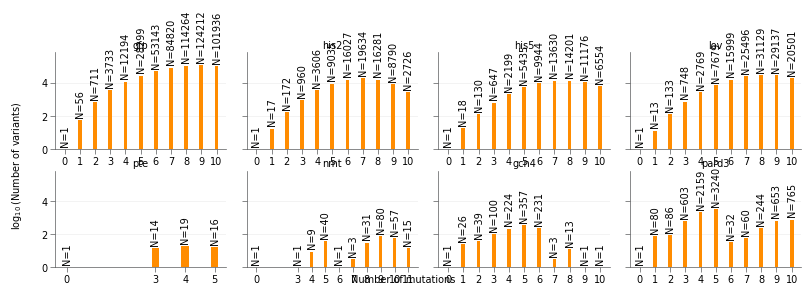

In [10]:
fig, axes, gof_summary = plot_gof_fraction_panels(
    dataset_order=[ "gfp", "his2", "his5", "lov", "pte", "nmt", "gcn4", "pard3"],
    nrows=2,
    ncols=4,
    figsize=(8.2, 2.5),
    text_size=7,
    show_positive_fraction=False
)
export_plot("mutation_distribution_per_dataset")
plt.show()

In [11]:
def old_format_log_tick(value, _):
    if np.isclose(value, 0):
        return "0"

    exponent = np.log10(value)

    if np.isclose(exponent, round(exponent)):
        exponent_text = str(int(round(exponent)))
    else:
        exponent_text = f"{exponent:.2f}".rstrip("0").rstrip(".")

    return rf"$10^{{{exponent_text}}}$"

def format_log_tick(value, _):
    if np.isclose(value, 0):
        return "0"

    mantissa, exponent = f"{value:.1E}".split("E")
    mantissa = mantissa.rstrip("0").rstrip(".")

    return f"{mantissa}E{int(exponent):+d}"
    
def plot_activity_by_mutation_panels(
    dataset_order, exclude_log=None, nrows=2, ncols=None, figsize=None, text_size=6,
    max_mutations=None, activity_columns=None, activity_color="steelblue",
    fraction_color="darkorange", annotate_fraction=True,
    activity_statistic="median", show_errorbars=False, sem=True
):
    

    if activity_statistic not in {"mean", "median"}:
        raise ValueError("activity_statistic must be either 'mean' or 'median'.")

    exclude_log = set(exclude_log or [])
    n_datasets = len(dataset_order)
    statistic_label = activity_statistic.title()
    error_statistic = "sem" if sem else "std"
    error_label = "SEM" if sem else "SD"

    activity_ylabel = f"{statistic_label} activity"

    if show_errorbars:
        activity_ylabel += f" ± {error_label}"

    if n_datasets == 0:
        raise ValueError("dataset_order is empty.")

    if nrows is None and ncols is None:
        nrows = min(2, n_datasets)

    if nrows is None:
        nrows = int(np.ceil(n_datasets / ncols))

    if ncols is None:
        ncols = int(np.ceil(n_datasets / nrows))

    if nrows * ncols < n_datasets:
        raise ValueError("nrows * ncols is smaller than the number of datasets.")

    if figsize is None:
        figsize = (3.0 * ncols, 2.6 * nrows)

    fig, axes_array = plt.subplots(
        nrows, ncols, figsize=figsize, sharex=False, sharey=False, squeeze=False
    )

    axes = axes_array.ravel()
    fraction_axes = []
    summaries = []

    def format_tick(value, _):
        return f"{value:.2g}"

    for panel_i, dataset in enumerate(dataset_order):
        ax = axes[panel_i]
        row = panel_i // ncols
        column = panel_i % ncols

        df = pd.read_csv(DATASET_PATHS[dataset])

        mutation_column = (
            "num_muts" if "num_muts" in df.columns else num_muts_column_name[dataset]
        )

        df[mutation_column] = pd.to_numeric(df[mutation_column], errors="coerce")
        df = df.dropna(subset=[mutation_column]).copy()
        df[mutation_column] = np.rint(df[mutation_column]).astype(int)

        if max_mutations is not None:
            df = df[df[mutation_column] <= max_mutations].copy()

        if activity_columns is not None and dataset in activity_columns:
            activity_column = activity_columns[dataset]
            raw_activity = pd.to_numeric(df[activity_column], errors="coerce")

        elif dataset == "gfp":
            raw_activity = 1 - pd.to_numeric(df["inactive"], errors="coerce")

        else:
            activity_column = datasets_and_activity[dataset]["activity_col"]
            raw_activity = pd.to_numeric(df[activity_column], errors="coerce")

        plot_data = pd.DataFrame({
            "nmut": df[mutation_column],
            "raw_activity": raw_activity
        }).dropna()

        if plot_data.empty:
            raise ValueError(f"{dataset}: no valid activity values were found.")

        raw_min = float(plot_data["raw_activity"].min())
        raw_max = float(plot_data["raw_activity"].max())
        normalize_activity = dataset not in exclude_log

        if normalize_activity:
            if raw_max <= 0:
                raise ValueError(
                    f"{dataset}: maximum activity is not positive. "
                    "Add this dataset to exclude_log."
                )

            if np.isclose(raw_min, raw_max):
                plot_data["activity"] = 0.0
            else:
                plot_data["activity"] = (
                    (plot_data["raw_activity"] - raw_min)
                    / (raw_max - raw_min)
                    * raw_max
                )
        else:
            plot_data["activity"] = plot_data["raw_activity"]

        activity_threshold = plot_data["raw_activity"].median()
        plot_data["positive"] = plot_data["raw_activity"] > activity_threshold

        summary = (
            plot_data.groupby("nmut")
            .agg(
                activity_value=("activity", activity_statistic),
                activity_sd=("activity", error_statistic),
                fraction_positive=("positive", "mean"),
                count=("activity", "size")
            )
            .sort_index()
        )

        summary["activity_sd"] = summary["activity_sd"].fillna(0)

        wt_rows = plot_data["nmut"] == 0

        if not wt_rows.any():
            raise ValueError(f"{dataset}: no WT variant with zero mutations was found.")

        wt_activity = plot_data.loc[wt_rows, "activity"].agg(activity_statistic)
        raw_wt_activity = plot_data.loc[
            wt_rows,
            "raw_activity"
        ].agg(activity_statistic)

        x = summary.index.to_numpy(dtype=int)
        activity_values = summary["activity_value"].to_numpy()
        activity_sd = summary["activity_sd"].to_numpy()
        fraction_positive = summary["fraction_positive"].to_numpy()

        activity_min = float(plot_data["activity"].min())
        activity_max = float(plot_data["activity"].max())

        if normalize_activity:
            y_min = 0.0
            y_max = activity_max
            use_log_scale = True

            positive_values = plot_data.loc[
                plot_data["activity"] > 0,
                "activity"
            ]

            if positive_values.empty:
                linear_threshold = 1.0
            else:
                linear_threshold = max(
                    positive_values.min() / 10,
                    np.finfo(float).eps
                )

        else:
            y_min = min(activity_min, 0.0)
            y_max = max(activity_max, 0.0)
            use_log_scale = False

        if np.isclose(y_min, y_max):
            padding = max(abs(y_max) * 0.1, 0.1)
            y_max += padding

        if show_errorbars:
            lower_error = np.minimum(
                activity_sd,
                np.maximum(activity_values - y_min, 0)
            )

            upper_error = np.minimum(
                activity_sd,
                np.maximum(y_max - activity_values, 0)
            )

            y_error = np.vstack([lower_error, upper_error])

            ax.errorbar(
                x,
                activity_values,
                yerr=y_error,
                color=activity_color,
                ecolor="black",
                marker="o",
                linestyle="none",
                markersize=3,
                elinewidth=0.8,
                capsize=2,
                capthick=0.8,
                zorder=3
            )

        else:
            ax.plot(
                x,
                activity_values,
                color=activity_color,
                marker="o",
                linestyle="none",
                markersize=3,
                zorder=3
            )

        ax.axhline(
            y=wt_activity,
            color="red",
            linestyle="--",
            linewidth=1,
            zorder=2
        )

        if use_log_scale:
            ax.set_yscale("symlog", linthresh=linear_threshold)
            ax.minorticks_off()
        else:
            ax.set_yscale("linear")

        ax.set_ylim(y_min, y_max)
        ax.set_yticks(np.unique([y_min, y_max]))

        if use_log_scale:
            ax.yaxis.set_major_formatter(FuncFormatter(format_log_tick))
            for label in ax.get_yticklabels():
                label.set_rotation(90)
                label.set_rotation_mode("anchor")
                label.set_horizontalalignment("right")
                label.set_verticalalignment("center")
        else:
            ax.yaxis.set_major_formatter(FuncFormatter(format_tick))

        fraction_ax = ax.twinx()
        fraction_axes.append(fraction_ax)

        fraction_ax.plot(
            x,
            fraction_positive,
            color=fraction_color,
            marker="s",
            linestyle=":",
            linewidth=1,
            markersize=3,
            zorder=4
        )

        fraction_ax.set_ylim(0, 1.12)
        fraction_ax.set_yticks([0, 1])
        fraction_ax.yaxis.set_major_formatter(FuncFormatter(format_tick))

        if annotate_fraction:
            n_annotations = min(4, len(x))
            annotation_indices = np.unique(
                np.round(np.linspace(0, len(x) - 1, n_annotations)).astype(int)
            )

            for index in annotation_indices:
                mutation_order = x[index]
                fraction = fraction_positive[index]

                vertical_offset = 3 if fraction < 0.95 else -8
                vertical_alignment = "bottom" if fraction < 0.95 else "top"

                fraction_ax.annotate(
                    f"{fraction:.2f}",
                    (mutation_order, fraction),
                    xytext=(0, vertical_offset),
                    textcoords="offset points",
                    ha="center",
                    va=vertical_alignment,
                    fontsize=text_size,
                    color="black",
                    bbox={
                        "boxstyle": "square,pad=0.12",
                        "facecolor": "white",
                        "edgecolor": "none",
                        "alpha": 0.65
                    }
                )

        x_ticks = np.unique([x[0], x[-1]])
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([str(value) for value in x_ticks])

        if len(x) == 1:
            ax.set_xlim(x[0] - 0.5, x[0] + 0.5)
        else:
            x_padding = max(0.4, 0.04 * (x[-1] - x[0]))
            ax.set_xlim(x[0] - x_padding, x[-1] + x_padding)

        is_bottom = panel_i + ncols >= n_datasets
        is_left = column == 0
        is_right = panel_i == min((row + 1) * ncols, n_datasets) - 1

        ax.set_xlabel(
            "Number of mutations" if is_bottom else "",
            fontsize=text_size
        )

        ax.set_ylabel(
            activity_ylabel if is_left else "",
            fontsize=text_size
        )

        fraction_ax.set_ylabel(
            "Fraction positive" if is_right else "",
            fontsize=text_size
        )

        ax.set_title(str(dataset).upper(), fontsize=text_size, pad=3)
        ax.tick_params(axis="both", labelsize=text_size, pad=2)
        fraction_ax.tick_params(axis="y", labelsize=text_size, pad=2)

        ax.set_axisbelow(True)
        ax.grid(axis="y", color="#EEEEEE", linewidth=0.6)
        ax.spines["top"].set_visible(False)
        fraction_ax.spines["top"].set_visible(False)

        summaries.append(
            summary.reset_index().assign(
                dataset=dataset,
                activity_threshold=activity_threshold,
                raw_wt_activity=raw_wt_activity,
                wt_activity=wt_activity,
                normalized=normalize_activity,
                log_scale=use_log_scale,
                activity_statistic=activity_statistic,
                error_statistic=error_statistic,
                errorbars_shown=show_errorbars
            )
        )

    for ax in axes[n_datasets:]:
        ax.set_visible(False)

    fig.subplots_adjust(
        #left=0.075, #right=0.925, bottom=0.10, top=0.94,
        wspace=0.40, hspace=0.30
    )

    summary_df = pd.concat(summaries, ignore_index=True)

    return fig, axes[:n_datasets], fraction_axes, summary_df

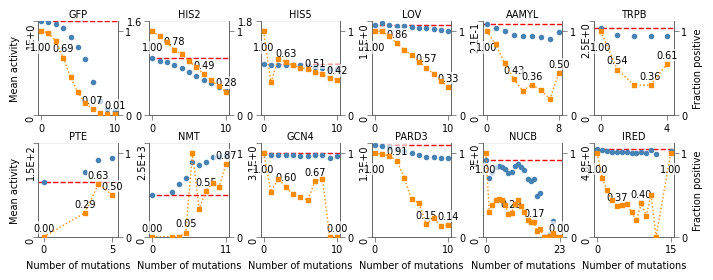

In [12]:
fig, axes, fraction_axes, activity_summary = plot_activity_by_mutation_panels(
    ["gfp", "his2", "his5", "lov", "aamyl", "trpb", "pte", "nmt", "gcn4", "pard3", "nucb", "ired"],
    sem=False,
    exclude_log=["his2", "his5"],
    figsize=(8.2, 2.8),
    text_size=7,
    activity_statistic="mean"
)

export_plot("activity_distribution")
plt.show()

In [13]:
def plot_dataset_composition_comparison(
    datasets_1,
    datasets_2,
    list_names=("Dataset group 1", "Dataset group 2"),
    dataset_names=None,
    colors=("steelblue", "darkorange"),
    figsize=(16, 4),
    text_size=7,
    max_mutations=None,
    log10_variants=True,
    cdf_grid_size=201,
    hamming_statistic="mean",
    hamming_error="sd",
    max_hamming_sequences=2000,
    hamming_bootstrap_iterations=20,
    random_seed=0,
    jitter=0.10,
    panel_12_wspace=0.16,
    outer_wspace=0.12,
    panel_width_ratios=(2.4, 1.4, 1.0),
    debug=True,
):
    from matplotlib.text import Text
    from scipy.spatial.distance import pdist

    if hamming_statistic not in {"mean", "median"}:
        raise ValueError("hamming_statistic must be 'mean' or 'median'.")
    if hamming_error not in {"sd", "sem", None}:
        raise ValueError("hamming_error must be 'sd', 'sem', or None.")
    if max_hamming_sequences < 2:
        raise ValueError("max_hamming_sequences must be at least 2.")
    if hamming_bootstrap_iterations < 1:
        raise ValueError("hamming_bootstrap_iterations must be at least 1.")
    if len(panel_width_ratios) != 3 or any(width <= 0 for width in panel_width_ratios):
        raise ValueError("panel_width_ratios must contain three positive values.")
    if panel_12_wspace < 0 or outer_wspace < 0:
        raise ValueError("panel_12_wspace and outer_wspace cannot be negative.")

    def calculate_hamming(sequence_df, row_indices, return_distances=False):
        sampled_sequences = sequence_df.iloc[row_indices].astype(str)
        sequence_codes = np.column_stack(
            [
                pd.factorize(sampled_sequences[column], sort=False)[0]
                for column in sampled_sequences.columns
            ]
        )
        distances = pdist(sequence_codes, metric="hamming") * sequence_codes.shape[1]
        estimate = (
            np.mean(distances) if hamming_statistic == "mean" else np.median(distances)
        )
        return float(estimate), distances if return_distances else None

    dataset_names = dataset_names or {}
    dataset_groups = [list(datasets_1), list(datasets_2)]
    rng = np.random.default_rng(random_seed)
    cdf_grid = np.linspace(0, 1, cdf_grid_size)

    composition_rows = []
    mutation_fraction_rows = []
    cdf_curves = {}

    for group_index, datasets in enumerate(dataset_groups):
        group_name = list_names[group_index]

        for dataset in datasets:
            if debug:
                print(f"\n[{dataset}] Loading dataset from group '{group_name}'")

            df = pd.read_csv(DATASET_PATHS[dataset])
            mutation_column = (
                "num_muts" if "num_muts" in df.columns else num_muts_column_name[dataset]
            )
            df[mutation_column] = pd.to_numeric(df[mutation_column], errors="coerce")
            df = df.dropna(subset=[mutation_column]).copy()
            df[mutation_column] = np.rint(df[mutation_column]).astype(int)

            if max_mutations is not None:
                df = df[df[mutation_column] <= max_mutations].copy()
            if df.empty:
                if debug:
                    print(f"[{dataset}] Skipped: no variants remain after filtering")
                continue

            relevant_columns = get_relevant_columns(dataset, df)
            ohe = get_one_hot_encoding(df, relevant_columns)
            mutation_counts = np.asarray(ohe.sum(axis=0)).ravel()
            mutation_fractions = mutation_counts / len(df)
            mutation_names = (
                ohe.columns.astype(str)
                if hasattr(ohe, "columns")
                else np.arange(ohe.shape[1]).astype(str)
            )

            wt_rows = df[mutation_column] == 0
            if wt_rows.any():
                wt_sequence = df.loc[wt_rows, relevant_columns].iloc[0]
                n_mutated_positions = int(
                    df[relevant_columns]
                    .ne(wt_sequence, axis="columns")
                    .any(axis=0)
                    .sum()
                )
            else:
                n_mutated_positions = int(
                    (df[relevant_columns].nunique(dropna=False) > 1).sum()
                )

            if debug:
                print(
                    f"[{dataset}] variants={len(df):,}, mutation features={ohe.shape[1]:,}, "
                    f"mutated positions={n_mutated_positions:,}"
                )

            sequence_df = df[relevant_columns]
            n_sequences = len(sequence_df)
            n_sample = min(max_hamming_sequences, n_sequences)

            if n_sequences < 2:
                hamming_value = np.nan
                hamming_sd = np.nan
                hamming_sem = np.nan
                hamming_iteration_values = []
                n_hamming_iterations = 0
                hamming_bootstrapped = False
                if debug:
                    print(f"[{dataset}] Hamming skipped: fewer than two sequences")
            elif n_sequences > max_hamming_sequences:
                hamming_iteration_values = []
                n_hamming_iterations = hamming_bootstrap_iterations
                hamming_bootstrapped = True

                if debug:
                    print(
                        f"[{dataset}] Bootstrapping Hamming distance: "
                        f"N={n_sample:,}, K={n_hamming_iterations}"
                    )

                for iteration in range(n_hamming_iterations):
                    sample_indices = rng.choice(n_sequences, size=n_sample, replace=False)
                    estimate, _ = calculate_hamming(sequence_df, sample_indices)
                    hamming_iteration_values.append(estimate)

                    if debug:
                        print(
                            f"[{dataset}] Hamming iteration {iteration + 1}/"
                            f"{n_hamming_iterations}: {estimate:.4f}"
                        )

                hamming_value = float(np.mean(hamming_iteration_values))
                hamming_sd = (
                    float(np.std(hamming_iteration_values, ddof=1))
                    if n_hamming_iterations > 1
                    else 0.0
                )
                hamming_sem = hamming_sd / np.sqrt(n_hamming_iterations)
            else:
                hamming_value, hamming_distances = calculate_hamming(
                    sequence_df, np.arange(n_sequences), return_distances=True
                )
                hamming_sd = (
                    float(np.std(hamming_distances, ddof=1))
                    if len(hamming_distances) > 1
                    else 0.0
                )
                hamming_sem = hamming_sd / np.sqrt(len(hamming_distances))
                hamming_iteration_values = [hamming_value]
                n_hamming_iterations = 1
                hamming_bootstrapped = False

                if debug:
                    print(f"[{dataset}] Exact Hamming distance from {n_sequences:,} sequences")

            if debug and n_sequences >= 2:
                print(
                    f"[{dataset}] Final Hamming={hamming_value:.4f}, "
                    f"SD={hamming_sd:.4f}, SEM={hamming_sem:.4f}"
                )

            display_name = dataset_names.get(dataset, dataset)
            composition_rows.append(
                {
                    "dataset": dataset,
                    "display_name": display_name,
                    "group": group_name,
                    "group_index": group_index,
                    "n_variants": len(df),
                    "n_mutations": ohe.shape[1],
                    "n_mutated_positions": n_mutated_positions,
                    "hamming_distance": hamming_value,
                    "hamming_sd": hamming_sd,
                    "hamming_sem": hamming_sem,
                    "n_hamming_sequences": n_sample,
                    "hamming_bootstrapped": hamming_bootstrapped,
                    "hamming_iterations": n_hamming_iterations,
                    "hamming_iteration_values": hamming_iteration_values,
                }
            )

            mutation_fraction_rows.extend(
                {
                    "dataset": dataset,
                    "display_name": display_name,
                    "group": group_name,
                    "group_index": group_index,
                    "mutation": mutation,
                    "count": count,
                    "fraction": fraction,
                }
                for mutation, count, fraction in zip(
                    mutation_names, mutation_counts, mutation_fractions
                )
            )

            sorted_fractions = np.sort(mutation_fractions)
            cdf_curves[(group_index, dataset)] = (
                np.searchsorted(sorted_fractions, cdf_grid, side="right")
                / len(sorted_fractions)
            )

    composition_df = pd.DataFrame(composition_rows)
    mutation_fraction_df = pd.DataFrame(mutation_fraction_rows)

    if composition_df.empty:
        raise ValueError("No datasets could be processed.")

    composition_df["log10_n_variants"] = np.log10(composition_df["n_variants"])
    variant_column = "log10_n_variants" if log10_variants else "n_variants"
    variant_label = "Variants in dataset (log10)" if log10_variants else "Variants in dataset"

    fig = plt.figure(figsize=figsize, layout="constrained")
    outer_grid = fig.add_gridspec(
        1, 3, width_ratios=panel_width_ratios, wspace=outer_wspace
    )
    left_grid = outer_grid[0].subgridspec(1, 2, wspace=panel_12_wspace)

    first_axis = fig.add_subplot(left_grid[0])
    axes = np.array(
        [
            first_axis,
            fig.add_subplot(left_grid[1], sharey=first_axis),
            fig.add_subplot(outer_grid[1]),
            fig.add_subplot(outer_grid[2]),
        ],
        dtype=object,
    )

    # Panels 1 and 2 share the variants y-axis.
    panel_columns = ["n_mutations", "n_mutated_positions"]

    for group_index, group_name in enumerate(list_names):
        group_df = composition_df[composition_df["group_index"] == group_index]

        for _, row in group_df.iterrows():
            for ax, panel_column in zip(axes[:2], panel_columns):
                ax.scatter(
                    row[panel_column],
                    row[variant_column],
                    color=colors[group_index],
                    s=35,
                    zorder=3,
                )
                ax.annotate(
                    row["display_name"],
                    (row[panel_column], row[variant_column]),
                    xytext=(3, 3),
                    textcoords="offset points",
                    fontsize=text_size,
                    color="black",
                )

    axes[0].set_xlabel("Number of observed\nmutations")
    axes[1].set_xlabel("Number of mutated\npositions")
    axes[0].set_ylabel(variant_label)
    axes[1].set_ylabel("")
    axes[1].tick_params(axis="y", labelleft=False)

    # Panel 3: per-dataset CDFs followed by the group mean ± between-dataset SD.
    for group_index, group_name in enumerate(list_names):
        group_curves = [
            cdf_curves[(group_index, dataset)]
            for dataset in dataset_groups[group_index]
            if (group_index, dataset) in cdf_curves
        ]
        if not group_curves:
            continue

        cdf_matrix = np.vstack(group_curves)
        mean_cdf = cdf_matrix.mean(axis=0)
        sd_cdf = (
            cdf_matrix.std(axis=0, ddof=1)
            if len(cdf_matrix) > 1
            else np.zeros_like(mean_cdf)
        )
        lower_cdf = np.clip(mean_cdf - sd_cdf, 0, 1)
        upper_cdf = np.clip(mean_cdf + sd_cdf, 0, 1)

        axes[2].plot(
            cdf_grid,
            mean_cdf,
            color=colors[group_index],
            linewidth=1.5,
            drawstyle="steps-post",
            label=group_name,
        )
        axes[2].fill_between(
            cdf_grid,
            lower_cdf,
            upper_cdf,
            step="post",
            color=colors[group_index],
            alpha=0.20,
            linewidth=0,
        )

    axes[2].set_xlim(0, 1)
    axes[2].set_ylim(0, 1)
    axes[2].set_xlabel("Fraction of variants containing a mutation")
    axes[2].set_ylabel("Cumulative fraction\nof mutations")
    axes[2].legend(frameon=False, fontsize=text_size)

    # Panel 4: pairwise Hamming distances.
    for group_index, group_name in enumerate(list_names):
        group_df = composition_df[composition_df["group_index"] == group_index]
        x_positions = group_index + rng.uniform(-jitter, jitter, size=len(group_df))

        for x_position, (_, row) in zip(x_positions, group_df.iterrows()):
            if pd.isna(row["hamming_distance"]):
                continue

            if hamming_error == "sd":
                error = row["hamming_sd"]
            elif hamming_error == "sem":
                error = row["hamming_sem"]
            else:
                error = None

            axes[3].errorbar(
                x_position,
                row["hamming_distance"],
                yerr=error,
                fmt="o",
                color=colors[group_index],
                ecolor=colors[group_index],
                capsize=2,
                markersize=5,
                alpha=0.85,
            )
            axes[3].annotate(
                row["display_name"],
                (x_position, row["hamming_distance"]),
                xytext=(3, 3),
                textcoords="offset points",
                fontsize=text_size,
                color="black",
            )

    axes[3].set_xticks(range(len(list_names)))
    axes[3].set_xticklabels(list_names)
    axes[3].set_ylabel(f"{hamming_statistic.title()} pairwise\nHamming distance")

    for ax in axes:
        ax.tick_params(labelsize=text_size, colors="black")
        ax.xaxis.label.set_color("black")
        ax.yaxis.label.set_color("black")
        ax.set_axisbelow(True)
        ax.grid(color="#EEEEEE", linewidth=0.6)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    for text_artist in fig.findobj(match=Text):
        text_artist.set_fontsize(text_size)

    return fig, axes, composition_df, mutation_fraction_df


[gfp] Loading dataset from group 'This benchmark'
[gfp] variants=523,369, mutation features=78, mutated positions=22
[gfp] Bootstrapping Hamming distance: N=5,000, K=30
[gfp] Hamming iteration 1/30: 8.7450
[gfp] Hamming iteration 2/30: 8.8030
[gfp] Hamming iteration 3/30: 8.7377
[gfp] Hamming iteration 4/30: 8.7519
[gfp] Hamming iteration 5/30: 8.7720
[gfp] Hamming iteration 6/30: 8.7828
[gfp] Hamming iteration 7/30: 8.7911
[gfp] Hamming iteration 8/30: 8.7768
[gfp] Hamming iteration 9/30: 8.7656
[gfp] Hamming iteration 10/30: 8.7462
[gfp] Hamming iteration 11/30: 8.7517
[gfp] Hamming iteration 12/30: 8.7747
[gfp] Hamming iteration 13/30: 8.7578
[gfp] Hamming iteration 14/30: 8.7902
[gfp] Hamming iteration 15/30: 8.7531
[gfp] Hamming iteration 16/30: 8.7778
[gfp] Hamming iteration 17/30: 8.7566
[gfp] Hamming iteration 18/30: 8.7915
[gfp] Hamming iteration 19/30: 8.7662
[gfp] Hamming iteration 20/30: 8.7338
[gfp] Hamming iteration 21/30: 8.7599
[gfp] Hamming iteration 22/30: 8.7705
[gf

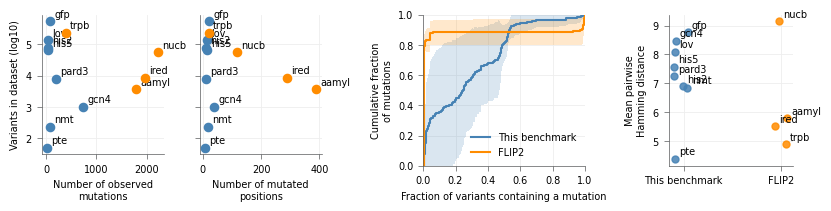

In [14]:
fig, axes, composition_df, mutation_fraction_df = (
    plot_dataset_composition_comparison(
        datasets_1=["gfp", "lov", "pard3", "his2", "his5", "nmt", "gcn4", "pte"],
        datasets_2=["trpb", "aamyl", "ired", "nucb"],
        list_names=("This benchmark", "FLIP2"),
        hamming_statistic="mean",
        hamming_error=None,
        max_hamming_sequences=5000,
        hamming_bootstrap_iterations=30,
        figsize=(8.2, 2),
        panel_12_wspace=0.01,
        panel_width_ratios=(2.8, 1.3, 1.0),
        #panel_width_ratios=(1.2, 1.2, 1.8, 1.2),
        text_size=7,
    )
)

export_plot("flip2_comparision")
plt.show()

In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
from matplotlib.text import Text


def plot_mds_embeddings(
    embeddings,
    dataset_names,
    wt_distances=None,
    figsize=None,
    text_size=7,
    point_size=4,
    wt_size=120,
    alpha=0.85,
    cmap="viridis",
    color_range=None,
    share_limits=False,
    panel_gap=0.28,
    grid_intervals=4,
):
    """
    Plot MDS embeddings side by side with a shared WT-distance colorbar.

    Each panel has the same physical box size but may use independent
    x- and y-axis scales.
    """
    if len(embeddings) != len(dataset_names):
        raise ValueError("embeddings and dataset_names must have the same length.")
    if not embeddings:
        raise ValueError("embeddings is empty.")
    if wt_distances is not None and len(wt_distances) != len(embeddings):
        raise ValueError("wt_distances must have one array per embedding.")
    if panel_gap < 0:
        raise ValueError("panel_gap cannot be negative.")
    if grid_intervals < 2:
        raise ValueError("grid_intervals must be at least 2.")

    coordinates = []

    for embedding in embeddings:
        coords = (
            np.load(Path(embedding).expanduser())
            if isinstance(embedding, (str, Path))
            else embedding
        )
        coords = np.asarray(coords, dtype=float)

        if coords.ndim != 2 or coords.shape[1] < 2:
            raise ValueError(
                f"Each embedding must have shape (n, >=2); got {coords.shape}."
            )
        if len(coords) == 0:
            raise ValueError("Embeddings cannot be empty.")

        coordinates.append(coords)

    distances = []

    for i, coords in enumerate(coordinates):
        if wt_distances is None:
            distance = np.linalg.norm(coords - coords[0], axis=1)
        else:
            distance = np.asarray(wt_distances[i], dtype=float).reshape(-1)

            if len(distance) == len(coords) - 1:
                distance = np.concatenate([[0.0], distance])

            if len(distance) != len(coords):
                raise ValueError(
                    f"WT distances for {dataset_names[i]!r} have length "
                    f"{len(distance)}, but the embedding has {len(coords)} rows."
                )

        distances.append(distance)

    finite_distances = np.concatenate(
        [distance[np.isfinite(distance)] for distance in distances]
    )

    if len(finite_distances) == 0:
        raise ValueError("No finite WT distances were found.")

    if color_range is None:
        color_min = 0.0
        color_max = float(finite_distances.max())
        color_max = color_max if color_max > color_min else color_min + 1
    else:
        if len(color_range) != 2:
            raise ValueError("color_range must contain exactly two values.")

        color_min, color_max = map(float, color_range)

        if not np.isfinite([color_min, color_max]).all() or color_max <= color_min:
            raise ValueError(
                "color_range must contain finite values with maximum > minimum."
            )

    norm = Normalize(vmin=color_min, vmax=color_max)

    n_panels = len(coordinates)

    if figsize is None:
        figsize = (3.35 * n_panels + 0.9, 3.4)

    fig, axes_array = plt.subplots(
        1,
        n_panels,
        figsize=figsize,
        squeeze=False,
        constrained_layout=True,
    )

    fig.set_constrained_layout_pads(
        w_pad=panel_gap,
        h_pad=0.08,
        wspace=0.04,
        hspace=0,
    )

    axes = axes_array.ravel()

    for panel_i, (ax, coords, distance, dataset) in enumerate(
        zip(axes, coordinates, distances, dataset_names)
    ):
        ax.scatter(
            coords[1:, 0],
            coords[1:, 1],
            c=distance[1:],
            cmap=cmap,
            norm=norm,
            s=point_size,
            alpha=alpha,
            linewidth=0,
            rasterized=True,
        )

        ax.scatter(
            coords[0, 0],
            coords[0, 1],
            s=wt_size,
            marker="*",
            color="black",
            edgecolor="white",
            linewidth=0.7,
            zorder=4,
        )

        ax.set_title(str(dataset))
        ax.set_xlabel("MDS 1")
        ax.set_ylabel("MDS 2" if panel_i == 0 else "")

        # Equal physical box sizes without forcing shared numerical scales.
        ax.set_aspect("auto")
        ax.set_box_aspect(1)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(True)

    if share_limits:
        all_x = np.concatenate([coords[:, 0] for coords in coordinates])
        all_y = np.concatenate([coords[:, 1] for coords in coordinates])

        x_padding = max(0.05 * np.ptp(all_x), 1e-6)
        y_padding = max(0.05 * np.ptp(all_y), 1e-6)

        for ax in axes:
            ax.set_xlim(all_x.min() - x_padding, all_x.max() + x_padding)
            ax.set_ylim(all_y.min() - y_padding, all_y.max() + y_padding)

    for ax in axes:
        x_min, x_max = ax.get_xlim()
        y_min, y_max = ax.get_ylim()

        # Label only the minimum and maximum values.
        ax.set_xticks([x_min, x_max])
        ax.set_yticks([y_min, y_max])

        # Unlabeled interior ticks provide the gridlines.
        ax.set_xticks(
            np.linspace(x_min, x_max, grid_intervals + 1)[1:-1],
            minor=True,
        )
        ax.set_yticks(
            np.linspace(y_min, y_max, grid_intervals + 1)[1:-1],
            minor=True,
        )

        ax.tick_params(which="minor", length=0)
        ax.grid(which="minor", color="#E8E8E8", linewidth=0.6)

    mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    mappable.set_array([])

    colorbar = fig.colorbar(
        mappable,
        ax=axes.tolist(),
        pad=0.02,
        fraction=0.025,
        shrink=0.82,
    )

    colorbar.set_label(
        "Hamming distance from WT"
        if wt_distances is not None
        else "MDS distance from WT"
    )

    for text_artist in fig.findobj(match=Text):
        text_artist.set_fontsize(text_size)

    return fig, axes, colorbar, distances

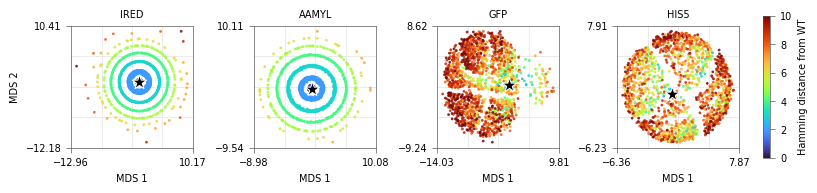

In [16]:
mds_embeddings_path = "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/epistasis_and_zs_analyses/mds_landscapes/"
embedding_paths = [
    "%s/ired_hamming_mds_coordinates.npy" % mds_embeddings_path,
    "%s/aamyl_hamming_mds_coordinates.npy" % mds_embeddings_path,
    "%s/gfp_hamming_mds_coordinates.npy" % mds_embeddings_path,
    "%s/his5_hamming_mds_coordinates.npy" % mds_embeddings_path,
]

def hamming_distance_from_wt(dataset):
    a = np.load("%s/%s_hamming_distance.npy" % (mds_embeddings_path, dataset))
    return(a[0,:])





# gfp_wt_distance = gfp_hamming_matrix[0, :]
# trpb_wt_distance = trpb_hamming_matrix[0, :]
# his_wt_distance = his_hamming_matrix[0, :]

fig, axes, colorbar, distances = plot_mds_embeddings(
    embedding_paths,
    ["IRED", "AAMYL", "GFP", "HIS5"],
    wt_distances=[
        hamming_distance_from_wt("ired"),
        hamming_distance_from_wt("aamyl"),
        hamming_distance_from_wt("gfp"),
        hamming_distance_from_wt("his5"),
    ],
    figsize=(8, 2),
    text_size=7,
    point_size=4,
    panel_gap=0.01,
    cmap="turbo"

)

export_plot("landscape_mds_example")
plt.show()

In [17]:
import pickle as pkl

def mutation_order_distribution(values, max_mutations=10):
    values = pd.to_numeric(pd.Series(values), errors="coerce").dropna().astype(int)
    values = values[(values >= 1) & (values <= max_mutations)]

    if values.empty:
        raise ValueError(f"No variants with 1-{max_mutations} mutations were found.")

    counts = np.bincount(values, minlength=max_mutations + 1)[1:max_mutations + 1]
    return counts / counts.sum()

def plot_mutation_distribution_comparison(
    dataset_order,
    muts_pkl_path="ProtGymMulti_muts.pkl",
    excluded_proteingym_datasets=None,
    max_mutations=10,
    figsize=(2.75, 2.75),
    text_size=7,
    group_gap=0.20,
    show_legend=True,
):
    if not dataset_order:
        raise ValueError("dataset_order is empty.")
    if not 0 <= group_gap < 1:
        raise ValueError("group_gap must be between 0 and 1.")

    if excluded_proteingym_datasets is None:
        excluded_proteingym_datasets = [
            "F7YBW8_MESOW_Ding_2023.csv",
            "GCN4_YEAST_Staller_2018.csv",
            "PHOT_CHLRE_Chen_2023.csv",
            "HIS7_YEAST_Pokusaeva_2019.csv",
        ]

    excluded_stems = {
        Path(dataset).stem
        for dataset in excluded_proteingym_datasets
    }

    with open(muts_pkl_path, "rb") as file:
        muts_pkl = pkl.load(file)

    proteingym_distributions = []

    for dataset_name, mutation_orders in muts_pkl.items():
        if Path(str(dataset_name)).stem in excluded_stems:
            continue

        try:
            distribution = mutation_order_distribution(
                mutation_orders,
                max_mutations=max_mutations,
            )
        except ValueError:
            continue

        proteingym_distributions.append(distribution)

    if not proteingym_distributions:
        raise ValueError("No unused ProteinGym datasets were found.")

    our_distributions = []

    for dataset in dataset_order:
        df = pd.read_csv(DATASET_PATHS[dataset])

        mutation_column = (
            "num_muts"
            if "num_muts" in df.columns
            else num_muts_column_name[dataset]
        )

        our_distributions.append(
            mutation_order_distribution(
                df[mutation_column],
                max_mutations=max_mutations,
            )
        )

    proteingym_mean = np.stack(proteingym_distributions).mean(axis=0)
    our_mean = np.stack(our_distributions).mean(axis=0)

    x = np.arange(1, max_mutations + 1)

    # Bars within a group touch; group_gap separates consecutive groups.
    bar_width = (1 - group_gap) / 2
    proteingym_x = x - bar_width / 2
    our_x = x + bar_width / 2

    fig, ax = plt.subplots(figsize=figsize)

    ax.set_axisbelow(True)
    ax.grid(
        which="both",
        linestyle="--",
        linewidth=0.25,
        alpha=0.7,
    )

    ax.bar(
        proteingym_x,
        proteingym_mean,
        width=bar_width,
        color="#91A2FF",
        label="ProteinGym multi-mutant datasets\n(not used in this study)",
    )

    ax.bar(
        our_x,
        our_mean,
        width=bar_width,
        color="#FFD199",
        label="Datasets used in this study",
    )

    ax.set_xlabel("Number of mutations", fontsize=text_size)
    ax.set_ylabel("Fraction of sequences", fontsize=text_size)
    ax.set_xticks(x)
    ax.tick_params(axis="both", labelsize=text_size)

    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

    if show_legend:
        ax.legend(fontsize=text_size, frameon=False)

    fig.tight_layout()

    summary = pd.DataFrame({
        "num_mutations": x,
        "ProteinGym not used": proteingym_mean,
        "Datasets used in this study": our_mean,
    })

    return fig, ax, summary

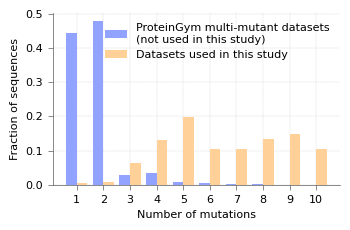

In [18]:

dataset_order = [
    "gcn4",
    "pard3",
    "pte",
    "nmt",
    "lov",
    "gfp",
    "his2",
    "his5",
    
]

fig, ax, mutation_summary = plot_mutation_distribution_comparison(
    dataset_order=dataset_order,
    text_size=8,
    figsize=(3.6,2.4),
    muts_pkl_path="/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/ProtGymMulti_muts.pkl",
)


export_plot("mutation_distribution")
plt.show()

In [19]:


METRIC_LABELS = {
    "r2": "R²",
    "spearman": "Spearman correlation",
    "auc": "ROC-AUC",
    "false_positive_count": "Number of false positives",
    "false_negative_count": "Number of false negatives",
    "total_error_count": "Total classification errors",
    "positive_train_count": "Positive sequences in train",
    "negative_train_count": "Negative sequences in train",
}

METRIC_ALIASES = {"roc": "auc", "roc_auc": "auc", "r²": "r2"}


def _metrics(metrics):
    metrics = [metrics] if isinstance(metrics, str) else list(metrics)
    metrics = [str(metric).lower().replace("-", "_") for metric in metrics]
    metrics = [METRIC_ALIASES.get(metric, metric) for metric in metrics]
    metrics = list(dict.fromkeys(metrics))
    unknown = [m for m in metrics if m not in METRIC_LABELS]
    if unknown:
        raise ValueError(f"Unknown metrics: {unknown}. Choose from {list(METRIC_LABELS)}")
    return metrics


def _long_metrics(df, metrics):
    metrics = _metrics(metrics)
    missing = [m for m in metrics if m not in df]
    if missing:
        raise ValueError(f"Missing metric columns: {missing}")

    ids = [column for column in df.columns if column not in metrics]
    out = df.melt(ids, metrics, var_name="metric", value_name="value")
    out["value"] = pd.to_numeric(out["value"], errors="coerce")
    out = out[np.isfinite(out["value"])]
    out = out[(out["metric"] != "r2") | (out["value"] >= 0)]
    out["Metric"] = out["metric"].map(METRIC_LABELS)
    if out.empty:
        raise ValueError("No finite values remain after metric filtering.")
    return out, metrics


def _select_metrics(df, metrics, datasets_by_metric=None):
    if datasets_by_metric is None:
        return _long_metrics(df, metrics)

    selection = {
        _metrics([metric])[0]: list(datasets)
        for metric, datasets in datasets_by_metric.items()
    }
    out, metrics = _long_metrics(df, list(selection))
    keep = np.zeros(len(out), dtype=bool)
    for metric, datasets in selection.items():
        keep |= (out["metric"] == metric) & out["dataset"].isin(datasets)
    out = out[keep]
    if out.empty:
        raise ValueError("No rows match datasets_by_metric.")
    return out, metrics


def _dataset_order(df, dataset_order):
    available = set(df["dataset"].dropna())
    order = [dataset for dataset in dataset_order if dataset in available]
    if not order:
        raise ValueError("None of the requested datasets are present in the results.")
    return order


def _make_panels(n, nrows, figsize=None, sharex=False, sharey=True):
    nrows = min(max(1, nrows), n)
    ncols = math.ceil(n / nrows)
    figsize = figsize or (3 * ncols, 2.7 * nrows)
    fig, grid = plt.subplots(
        nrows, ncols, figsize=figsize, sharex=sharex, sharey=sharey, squeeze=False
    )
    flat = grid.ravel()
    for ax in flat[n:]:
        ax.set_visible(False)
    return fig, flat[:n]


def _y_limits(plot_df, metrics, auc_from_half=False):
    if len(metrics) == 1 and metrics[0] == "auc" and auc_from_half:
        return 0.5, 1
    if set(metrics) <= {"r2", "spearman", "auc"}:
        return (-1 if "spearman" in metrics else 0), 1
    upper = max(1, plot_df["value"].max() * 1.05)
    return (-1 if "spearman" in metrics else 0), upper


def _decorate(ax, metrics, ylim):
    references = {0.5 if metric == "auc" else 0 for metric in metrics}
    for reference in sorted(references):
        ax.axhline(reference, color="black", linestyle="--", linewidth=0.8, zorder=0)
    ax.set_ylim(*ylim)


def _integer_axis(ax, values):
    values = np.sort(pd.unique(values))
    ax.set_xticks(values)
    if len(values) == 1:
        ax.set_xlim(values[0] - 0.5, values[0] + 0.5)
    elif len(values) > 1:
        ax.set_xlim(values[0] - 0.25, values[-1] + 0.25)


def _log_x_axis(ax, values):
    values = np.sort(pd.unique(values))
    ax.set_xscale("log")
    ax.set_xticks(values[[0, -1]] if len(values) > 1 else values)
    ax.set_xticklabels([f"{value:g}" for value in ax.get_xticks()])
    ax.xaxis.set_minor_formatter(NullFormatter())
    if len(values) == 1:
        ax.set_xlim(values[0] / 1.25, values[0] * 1.25)
    else:
        padding = 10 ** (0.04 * (np.log10(values[-1]) - np.log10(values[0])))
        ax.set_xlim(values[0] / padding, values[-1] * padding)
    ax.tick_params(axis="x", which="major", labelbottom=True)
    labels = ax.get_xticklabels()
    if len(labels) > 1:
        labels[0].set_ha("left")
        labels[-1].set_ha("right")


def _finish(
    fig,
    axes,
    show_legend,
    text_size,
    wspace=0.04,
    hspace=0.22,
    xlabel=None,
    ylabel=None,
    xlabel_pad=0.008,
    ylabel_pad=0.008,
):
    legend_items = {}
    for ax in axes:
        legend = ax.get_legend()
        if legend is not None:
            handles, labels = ax.get_legend_handles_labels()
            legend_items.update(
                (label, handle)
                for handle, label in zip(handles, labels)
                if label and not label.startswith("_")
            )
            legend.remove()

    labels = list(legend_items)
    if show_legend and labels:
        ncols = min(len(labels), max(1, int(fig.get_figwidth() / 1.3)))
        legend_rows = math.ceil(len(labels) / ncols)
        top = max(0.80, 0.98 - 0.045 * legend_rows)
        fig.legend(
            list(legend_items.values()), labels, loc="upper center",
            bbox_to_anchor=(0.5, 0.985), ncol=ncols, frameon=False
        )
    else:
        top = 0.995

    fig.tight_layout(rect=(0.01, 0.01, 0.995, top), pad=0.1, w_pad=0.05, h_pad=0.05)
    xlabel_room = text_size / (72 * fig.get_figheight()) + xlabel_pad if xlabel else 0
    ylabel_room = text_size / (72 * fig.get_figwidth()) + ylabel_pad if ylabel else 0
    fig.subplots_adjust(
        left=fig.subplotpars.left + ylabel_room,
        bottom=fig.subplotpars.bottom + xlabel_room,
        wspace=wspace,
        hspace=hspace,
    )

    for artist in fig.findobj(match=Text):
        artist.set_fontsize(text_size)

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    xlabels = [label for ax in axes for label in ax.get_xticklabels() if label.get_visible()]
    ylabels = [label for ax in axes for label in ax.get_yticklabels() if label.get_visible()]

    if xlabel:
        tick_bottom = min(label.get_window_extent(renderer).y0 for label in xlabels)
        tick_bottom /= fig.bbox.height
        fig.supxlabel(
            xlabel, y=max(0.002, tick_bottom - xlabel_pad), va="top", fontsize=text_size
        )
    if ylabel:
        tick_left = min(label.get_window_extent(renderer).x0 for label in ylabels)
        tick_left /= fig.bbox.width
        fig.supylabel(
            ylabel, x=max(0.002, tick_left - ylabel_pad), ha="right", fontsize=text_size
        )


def plot_fraction_panels(
    results,
    dataset_order,
    metrics=("r2",),
    datasets_by_metric=None,
    nrows=2,
    show_legend=True,
    figsize=None,
    text_size=7,
    errorbar="sd",
    palette="tab10",
    wspace=0.04,
    hspace=0.22,
    xlabel_pad=0.008,
    ylabel_pad=0.008,
):
    """Dataset panels of held-out metrics versus logged training-set size."""
    data = results[(results["regime"] == "random") & (results["n_train"] > 0)].copy()
    data, metrics = _select_metrics(data, metrics, datasets_by_metric)
    order = _dataset_order(data, dataset_order)
    data = data[data["dataset"].isin(order)]
    labels = [METRIC_LABELS[metric] for metric in metrics]
    y_min = float(data["value"].min())
    ylim = (y_min if y_min < 1 else 0.95, 1)
    fig, axes = _make_panels(len(order), nrows, figsize, sharex=False, sharey=True)

    for ax, dataset in zip(axes, order):
        panel = data[data["dataset"] == dataset]
        sns.lineplot(
            data=panel, x="n_train", y="value", hue="Metric",
            hue_order=labels, palette=palette, marker="o", estimator="mean",
            errorbar=errorbar, legend=show_legend, ax=ax
        )
        ax.set(xlabel="", ylabel="")
        ax.set_title(dataset, pad=1)
        _log_x_axis(ax, panel["n_train"])
        _decorate(ax, panel["metric"].unique(), ylim)

    ylabel = "Value" if len(metrics) > 1 else METRIC_LABELS[metrics[0]]
    _finish(
        fig, axes, show_legend, text_size, wspace, hspace,
        "Number of training sequences (log scale)", ylabel, xlabel_pad, ylabel_pad
    )
    return fig, axes



def _plot_exact_order_panels(
    results,
    dataset_order,
    metrics,
    datasets_by_metric,
    panel_column,
    panel_values,
    x,
    title,
    xlabel,
    train_fraction,
    nrows,
    show_legend,
    figsize,
    text_size,
    errorbar,
    palette,
    wspace,
    hspace,
    xlabel_pad,
    ylabel_pad,
):
    data = results[
        (results["regime"] == "mutation")
        & (results["test_scope"] == "exact_order")
        & results[panel_column].isin(panel_values)
        & np.isclose(results["requested_train_amount"], train_fraction)
    ].copy()
    data, metrics = _select_metrics(data, metrics, datasets_by_metric)
    order = _dataset_order(data, dataset_order)
    data = data[data["dataset"].isin(order)]
    panels = [value for value in panel_values if (data[panel_column] == value).any()]
    if not panels:
        raise ValueError("No matching exact-order results were found.")

    labels = [METRIC_LABELS[metric] for metric in metrics]
    colors = dict(zip(order, sns.color_palette(palette, len(order))))
    ylim = _y_limits(data, metrics)
    fig, axes = _make_panels(len(panels), nrows, figsize, sharex=False, sharey=True)

    for ax, panel_value in zip(axes, panels):
        panel = data[data[panel_column] == panel_value]
        kwargs = dict(
            data=panel, x=x, y="value", hue="dataset", hue_order=order,
            palette=colors, estimator="mean", errorbar=errorbar,
            legend=show_legend, ax=ax
        )
        if len(metrics) > 1:
            kwargs.update(style="Metric", style_order=labels, markers=True, dashes=True)
        else:
            kwargs["marker"] = "o"
        sns.lineplot(**kwargs)
        ax.set(title=title(panel_value), xlabel="", ylabel="")
        _integer_axis(ax, panel[x])
        _decorate(ax, panel["metric"].unique(), ylim)

    ylabel = "Value" if len(metrics) > 1 else METRIC_LABELS[metrics[0]]
    _finish(
        fig, axes, show_legend, text_size, wspace, hspace,
        xlabel, ylabel, xlabel_pad, ylabel_pad
    )
    return fig, axes


def plot_test_order_by_train_k(
    results,
    dataset_order,
    metrics=("r2",),
    datasets_by_metric=None,
    train_ks=range(1, 7),
    train_fraction=1.0,
    nrows=1,
    show_legend=True,
    figsize=None,
    text_size=7,
    errorbar="sd",
    palette="tab10",
    wspace=0.04,
    hspace=0.22,
    xlabel_pad=0.008,
    ylabel_pad=0.008,
):
    return _plot_exact_order_panels(
        results, dataset_order, metrics, datasets_by_metric,
        "k", list(train_ks), "test_order",
        lambda value: f"Train on mutation orders ≤ {value}",
        "Exact test mutation order", train_fraction, nrows,
        show_legend, figsize, text_size, errorbar, palette, wspace, hspace,
        xlabel_pad, ylabel_pad
    )


def _parse_indices(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)
    if value is None or (np.isscalar(value) and pd.isna(value)):
        return []
    if isinstance(value, (list, tuple, np.ndarray, pd.Series)):
        return list(value)
    raise TypeError(f"Expected an index list, received {type(value)}")
    """Convert classification-error output into the mutation-results schema."""
    count_columns = {
        "positive_train_count": "positive_indices_train",
        "negative_train_count": "negative_indices_train",
        "false_positive_count": "false_positive_indices_test",
        "false_negative_count": "false_negative_indices_test",
    }
    required = ["dataset", "mutations_in_train", "test_order", *count_columns.values()]
    missing = [column for column in required if column not in errors]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    out = errors.copy()
    for count_column, index_column in count_columns.items():
        out[index_column] = out[index_column].map(_parse_indices)
        out[count_column] = out[index_column].str.len()

    out["total_error_count"] = out["false_positive_count"] + out["false_negative_count"]
    return out.assign(
        regime="mutation",
        test_scope="exact_order",
        k=out["mutations_in_train"],
        requested_train_amount=1.0,
        train_amount_type="fraction",
        train_fraction=1.0,
        repeat=0,
    )

In [20]:
results = pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/epistasis_and_zs_analyses/linear_baselines_predictability.csv")

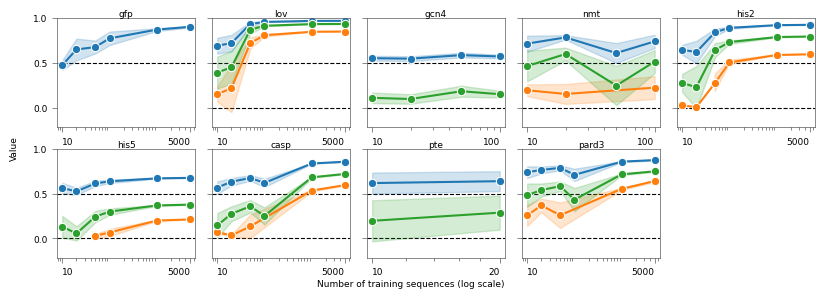

In [21]:
datasets_by_metric = {
    "auc": [
        "gfp", "lov", "gcn4", "nmt", "his2",
        "his5", "casp", "pte", "pard3",
    ],
    "r2": [
        "lov", "nmt", "his2",
        "his5", "casp", "pard3"
    ],
    "spearman": [
     "lov", "gcn4", "nmt", "his2",
        "his5", "casp", "pte", "pard3",
    ],
}

fig, axes = plot_fraction_panels(
    results,
    dataset_order=[
        "gfp", "lov", "gcn4", "nmt", "his2",
        "his5", "casp", "pte", "pard3",
    ],
    datasets_by_metric=datasets_by_metric,
    nrows=2,
    show_legend=False,
    figsize=(8.2, 3),
    text_size=6.5,
    hspace=0.2,
    wspace=0.125
    
)

export_plot("additive_model_comparision_by_subsample")
plt.show()

In [22]:
def plot_train_k_by_test_order(
    results,
    dataset_order,
    metrics=("r2",),
    datasets_by_metric=None,
    test_orders=range(3, 11),
    train_fraction=1.0,
    nrows=1,
    show_legend=True,
    figsize=None,
    text_size=7,
    errorbar="sd",
    palette="tab10",
    wspace=0.04,
    hspace=0.22,
    xlabel_pad=0.008,
    ylabel_pad=0.008,
):
    data = results[
        (results["regime"] == "mutation")
        & (results["test_scope"] == "exact_order")
        & results["test_order"].isin(test_orders)
        & np.isclose(results["requested_train_amount"], train_fraction)
    ].copy()

    data, _ = _select_metrics(data, metrics, datasets_by_metric)
    data = data[data["dataset"].isin(dataset_order)]

    fig, axes = _plot_exact_order_panels(
        results, dataset_order, metrics, datasets_by_metric,
        "test_order", list(test_orders), "k",
        lambda value: f"Exact test order = {value}",
        "Maximum training mutation order K", train_fraction, nrows,
        show_legend, figsize, text_size, errorbar, palette, wspace, hspace,
        xlabel_pad, ylabel_pad
    )

    y_min = data["value"].min()
    for ax in axes:
        ax.set_ylim(y_min, 1)

    return fig, axes

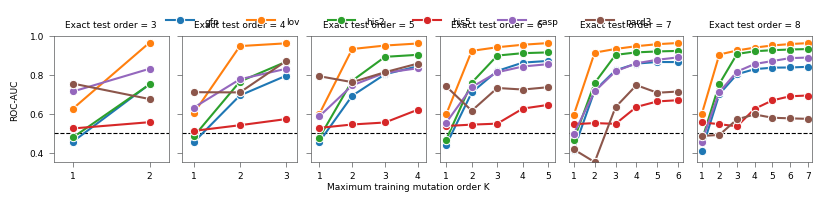

In [23]:
fig, axes = plot_train_k_by_test_order(
    results,
    dataset_order=[
        "gfp", "lov", "his2",
        "his5", "casp", "pard3",
    ],
    metrics=["auc"],
    #datasets_by_metric=datasets_by_metric,
    test_orders=range(3, 9),
    train_fraction=1.0,
    nrows=1,
    figsize=(8.2, 2),
    text_size=6.5,
    show_legend=True,
    errorbar="sd",
    wspace=0.12,
    hspace=0.25,
    xlabel_pad=0.006,
    ylabel_pad=0.006,
)

export_plot("additive_model_comparision_by_mut_test_regime")

plt.show()

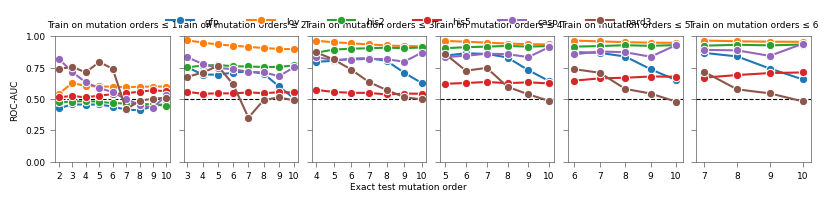

In [24]:
dataset_order=[
        "gfp", "lov", "his2",
        "his5", "casp", "pard3",
    ]
    
fig, axes = plot_test_order_by_train_k(
    results,
    dataset_order=dataset_order,
    metrics=["auc"],
    train_ks=range(1, 7),
    train_fraction=1.0,
    nrows=1,
    figsize=(8.2, 2),
    text_size=6.5,
    show_legend=True,
    errorbar="sd",
    wspace=0.12,
    hspace=0.25,
)

export_plot("additive_model_comparision_by_mut_train_regime")
plt.show()

In [25]:
def plot_all_all_grouped_bars(
    results,
    dataset_order,
    metrics=("auc", "r2", "spearman"),
    datasets_by_metric=None,
    figsize=None,
    text_size=7,
    palette="tab10",
    show_legend=True,
    ylim=None,
    bar_width=0.55,
):
    data = results[results["regime"] == "all_all"].copy()
    data, metrics = _select_metrics(data, metrics, datasets_by_metric)

    order = _dataset_order(data, dataset_order)
    data = data[data["dataset"].isin(order)]

    metric_labels = [METRIC_LABELS[metric] for metric in metrics]
    colors = dict(zip(metric_labels, sns.color_palette(palette, len(metric_labels))))

    if figsize is None:
        figsize = (max(8, 1.1 * len(order)), 3.5)

    fig, ax = plt.subplots(figsize=figsize)

    sns.barplot(
        data=data,
        x="dataset",
        y="value",
        hue="Metric",
        order=order,
        hue_order=metric_labels,
        palette=colors,
        errorbar=None,
        width=bar_width,
        ax=ax,
    )

    if ylim is None:
        ylim = (min(0, data["value"].min()), 1)

    _decorate(ax, data["metric"].unique(), ylim)

    ax.set_title("Train-all/test-all linear hyperplane")
    ax.set_xlabel("")
    ax.set_ylabel("Value")
    ax.tick_params(axis="x", rotation=45)

    _finish(fig, [ax], show_legend, text_size)

    return fig, ax

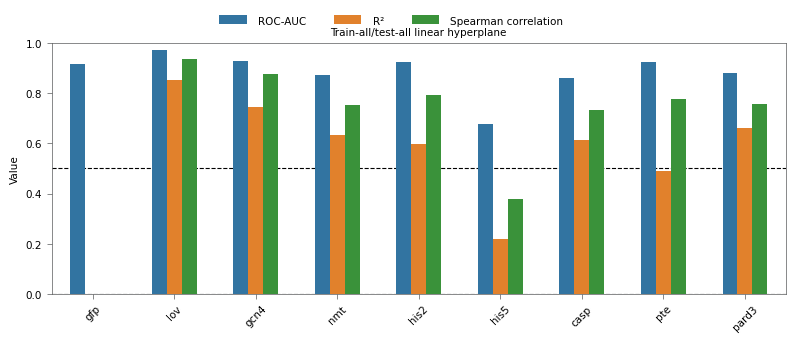

In [26]:

datasets_by_metric = {
    "auc": [
        "gfp", "lov", "gcn4", "nmt", "his2",
        "his5", "casp", "pte", "pard3",
    ],
    "r2": [
        "lov", "nmt", "his2",
        "his5", "casp", "pard3", "pte", "gcn4"
    ],
    "spearman": [
     "lov", "gcn4", "nmt", "his2",
        "his5", "casp", "pte", "pard3",
    ],
}


fig, ax = plot_all_all_grouped_bars(
    results,
    dataset_order=[
        "gfp", "lov", "gcn4", "nmt", "his2",
        "his5", "casp", "pte", "pard3",
    ],
    datasets_by_metric=datasets_by_metric,
    figsize=(8, 3.5),
    text_size=7.5,
    show_legend=True,
    ylim=(0, 1),
)

export_plot("additive_model_comparision_predictability_train_all_test_all")
plt.show()

In [27]:
def plot_complete_epistasis_summary(
    epistasis_results, dataset_order=None, font_size=11, figsize=None,
    pair_count_color="#4C4C4C", epistatic_count_color="#D73027"
):
    import ast

    category_map = {
        "no_epistasis_expected_positive": "No epistasis: positive",
        "no_epistasis_expected_negative": "No epistasis: negative",
        "negative_sign_epistasis": "Negative sign epistasis",
        "weak_positive_sign_epistasis": "Weak positive sign epistasis",
        "strong_positive_sign_epistasis": "Strong positive sign epistasis"
    }

    category_order = [
        "No epistasis: positive",
        "No epistasis: negative",
        "Negative sign epistasis",
        "Weak positive sign epistasis",
        "Strong positive sign epistasis"
    ]

    epistatic_types = [
        "negative_sign_epistasis",
        "weak_positive_sign_epistasis",
        "strong_positive_sign_epistasis"
    ]

    colors = {
        "No epistasis: positive": "#D9D9D9",
        "No epistasis: negative": "#737373",
        "Negative sign epistasis": "#D73027",
        "Weak positive sign epistasis": "#74ADD1",
        "Strong positive sign epistasis": "#2166AC"
    }

    def was_reversed(value):
        if isinstance(value, str):
            if not value.strip():
                return False
            value = ast.literal_eval(value)

        if value is None:
            return False

        if isinstance(value, dict):
            return any(len(indices) > 0 for indices in value.values())

        if isinstance(value, (list, tuple, set, np.ndarray)):
            return len(value) > 0

        return False

    plot_df = epistasis_results.copy()
    plot_df["category"] = plot_df["epistasis_type"].map(category_map)
    plot_df = plot_df[plot_df["category"].notna()].copy()
    plot_df["epistatic"] = plot_df["epistasis_type"].isin(epistatic_types)

    available_datasets = list(pd.unique(plot_df["dataset"]))

    if dataset_order is None:
        datasets = available_datasets
    else:
        datasets = [dataset for dataset in dataset_order if dataset in available_datasets]

    if not datasets:
        raise ValueError("None of the requested datasets were found.")

    plot_df = plot_df[plot_df["dataset"].isin(datasets)].copy()
    plot_df["reversed"] = plot_df["reverse_indices"].apply(was_reversed)

    # Pair counts and pair-type fractions
    counts = pd.crosstab(plot_df["dataset"], plot_df["category"]).reindex(
        index=datasets, columns=category_order, fill_value=0
    )

    epistatic_categories = [
        "Negative sign epistasis",
        "Weak positive sign epistasis",
        "Strong positive sign epistasis"
    ]

    total_counts = counts.sum(axis=1)
    epistatic_counts = counts[epistatic_categories].sum(axis=1)
    fractions = counts.div(total_counts, axis=0).mul(100)

    epistatic_fraction_from_counts = 100 * epistatic_counts / total_counts
    epistatic_fraction_from_composition = fractions[epistatic_categories].sum(axis=1)

    if not np.allclose(
        epistatic_fraction_from_counts,
        epistatic_fraction_from_composition
    ):
        raise ValueError("The count and composition calculations do not agree.")

    fractions = counts.div(total_counts, axis=0).mul(100)

    # Fraction reversed within each dataset and interaction type
    reversal_summary = (
        plot_df.groupby(["dataset", "category"], observed=True)
        .agg(total_pairs=("reversed", "size"), reversed_pairs=("reversed", "sum"))
        .reset_index()
    )

    reversal_summary["reversed_fraction_percent"] = (
        100 * reversal_summary["reversed_pairs"] / reversal_summary["total_pairs"]
    )

    reversal_fractions = reversal_summary.pivot(
        index="dataset", columns="category", values="reversed_fraction_percent"
    ).reindex(index=datasets, columns=category_order)

    present_categories = [
        category for category in category_order if counts[category].sum() > 0
    ]

    dataset_summary = pd.DataFrame({
        "dataset": datasets,
        "total_pairs": total_counts.to_numpy(),
        "epistatic_pairs": epistatic_counts.to_numpy()
    })

    pair_summary = (
        counts.stack()
        .rename("count")
        .reset_index()
        .merge(
            fractions.stack().rename("fraction_percent").reset_index(),
            on=["dataset", "category"]
        )
        .merge(dataset_summary, on="dataset")
    )

    # Figure layout
    if figsize is None:
        figsize = (max(12, 1.4 * len(datasets)), 8)

    fig = plt.figure(figsize=figsize)
    outer_grid = fig.add_gridspec(2, 1, height_ratios=[1, 1.1], hspace=0.55)
    top_grid = outer_grid[0].subgridspec(1, 2, wspace=0.30)

    ax_counts = fig.add_subplot(top_grid[0, 0])
    ax_fractions = fig.add_subplot(top_grid[0, 1])
    ax_reversals = fig.add_subplot(outer_grid[1])

    x = np.arange(len(datasets))
    bar_width = 0.42

    ax_counts.bar(
        x - bar_width / 2,
        total_counts.to_numpy(),
        width=bar_width,
        color=pair_count_color
    )

    ax_counts.bar(
        x + bar_width / 2,
        epistatic_counts.to_numpy(),
        width=bar_width,
        color=epistatic_count_color
    )

    ax_counts.set_xticks(x)
    ax_counts.set_xticklabels(datasets, rotation=45, ha="right")
    ax_counts.set_ylabel("Number of pairs", fontsize=font_size)
    ax_counts.set_title("Total and epistatic pair counts", fontsize=font_size + 2)
    ax_counts.set_xlabel("")
    ax_counts.set_yscale("log")

    # Top-right: fraction of each pair type
    fractions.plot(
        kind="bar", stacked=True, color=[colors[category] for category in category_order],
        width=0.8, legend=False, ax=ax_fractions
    )

    ax_fractions.set_ylim(0, 100)
    ax_fractions.set_title("Observed pair composition", fontsize=font_size + 2)
    ax_fractions.set_ylabel("Fraction of pairs (%)", fontsize=font_size)
    ax_fractions.set_xlabel("")

    # Bottom: fraction reversed, grouped by dataset
    reversal_fractions[present_categories].plot(
        kind="bar", stacked=False, color=[colors[category] for category in present_categories],
        width=0.8, legend=False, ax=ax_reversals
    )

    ax_reversals.set_ylim(0, 100)
    ax_reversals.set_title(
        "Pairs phenotype reversed by high-order interactions", fontsize=font_size + 2
    )
    ax_reversals.set_ylabel("Pairs reversed (%)", fontsize=font_size)
    ax_reversals.set_xlabel("")
    ax_reversals.tick_params(axis="x", rotation=45)

    for ax in [ax_counts, ax_fractions, ax_reversals]:
        ax.grid(False)
        ax.tick_params(axis="both", labelsize=font_size)

    fig.tight_layout()

    axes = {
        "pair_counts": ax_counts,
        "pair_fractions": ax_fractions,
        "reversal_fractions": ax_reversals
    }

    return fig, axes, pair_summary, reversal_summary

In [28]:
import ast

epi_df = pd.read_csv(
    "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/"
    "merged_datasets/epistasis_and_zs_analyses/epistasis_content.csv",
    converters={
        "reverse_indices": ast.literal_eval,
        "reverses_mutational_order": ast.literal_eval,
        "non_reverse_indices": ast.literal_eval,
        "non_reverses_mutational_order": ast.literal_eval,
    },
)


/tmp/ipykernel_2204154/140795560.py:199: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


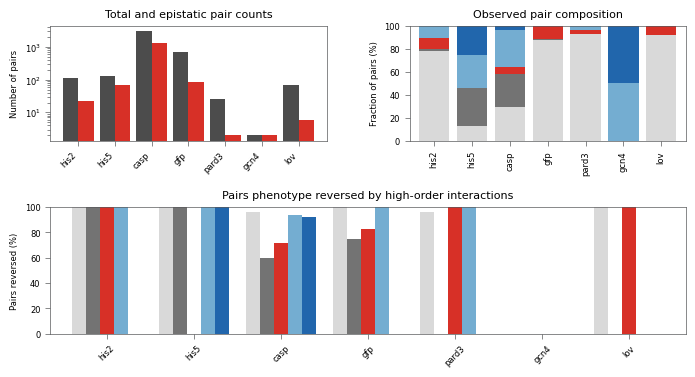

In [29]:

dataset_order = ["his2", "his5", "casp", "gfp","pard3", "pte", "gcn4", "nmt", "lov"]


fig, axes, pair_summary, rescue_summary = (
    plot_complete_epistasis_summary(
        epi_df,#[epi_df["epistasis_type"] == "no_epistasis_expected_positive"],
        dataset_order=dataset_order,
        font_size=6,
        figsize=(8.2, 4)
    )
)

export_plot("epistasis_pairs_content")

plt.show()

In [30]:
epi_df[epi_df["epistasis_type"] == "no_epistasis_expected_negative"]

,dataset,pair_identity,single_1_status,single_2_status,expected_phenotype,actual_phenotype,epistasis_type,is_epistatic,pair_indices,reverses_mutational_order,non_reverses_mutational_order,reverse_indices,non_reverse_indices
0,casp,"('A572:A>C', 'G586:G>P')",negative,positive,negative,negative,no_epistasis_expected_negative,False,[2],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 1, 4: 0, 5: 1, 6: 1, 7: 0, 8: 0, 9: 0, 10:...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [7599], 4: [], 5: [7490], 6: [11893], 7: [..."
3,casp,"('A572:A>C', 'L583:L>I')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[10],"{3: 0, 4: 2, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 0, 4: 0, 5: 0, 6: 2, 7: 0, 8: 0, 9: 0, 10:...","{3: [], 4: [4107, 14750], 5: [], 6: [], 7: [],...","{3: [], 4: [], 5: [], 6: [142, 15642], 7: [], ..."
5,casp,"('A572:A>C', 'L583:L>W')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[12],"{3: 2, 4: 1, 5: 0, 6: 0, 7: 0, 8: 1, 9: 0, 10:...","{3: 0, 4: 1, 5: 1, 6: 0, 7: 0, 8: 0, 9: 1, 10:...","{3: [13, 14], 4: [122], 5: [], 6: [], 7: [], 8...","{3: [], 4: [49], 5: [160], 6: [], 7: [], 8: []..."
8,casp,"('A572:A>C', 'N582:N>P')",negative,positive,negative,negative,no_epistasis_expected_negative,False,[37],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ..."
12,casp,"('A572:A>C', 'Q575:Q>C')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[42],"{3: 1, 4: 0, 5: 0, 6: 0, 7: 0, 8: 1, 9: 0, 10:...","{3: 0, 4: 1, 5: 1, 6: 1, 7: 0, 8: 0, 9: 2, 10:...","{3: [43], 4: [], 5: [], 6: [], 7: [], 8: [7035...","{3: [], 4: [1950], 5: [44], 6: [1011], 7: [], ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
28527,trpb,"('A104:A>Y', 'E105:E>R')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[228194],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 19, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [228178, 228179, 228180, 228181, 228182, 2..."
28528,trpb,"('A104:A>Y', 'E105:E>S')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[228214],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 19, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [228198, 228199, 228200, 228201, 228202, 2..."
28529,trpb,"('A104:A>Y', 'E105:E>T')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[228234],"{3: 1, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 18, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: [228223], 4: [], 5: [], 6: [], 7: [], 8: [...","{3: [228218, 228219, 228220, 228221, 228222, 2..."
28531,trpb,"('A104:A>Y', 'E105:E>W')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[228274],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 19, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [228258, 228259, 228260, 228261, 228262, 2..."


In [31]:
epi_df

,dataset,pair_identity,single_1_status,single_2_status,expected_phenotype,actual_phenotype,epistasis_type,is_epistatic,pair_indices,reverses_mutational_order,non_reverses_mutational_order,reverse_indices,non_reverse_indices
0,casp,"('A572:A>C', 'G586:G>P')",negative,positive,negative,negative,no_epistasis_expected_negative,False,[2],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 1, 4: 0, 5: 1, 6: 1, 7: 0, 8: 0, 9: 0, 10:...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [7599], 4: [], 5: [7490], 6: [11893], 7: [..."
1,casp,"('A572:A>C', 'L583:L>D')",negative,positive,negative,positive,weak_positive_sign_epistasis,True,[3],"{3: 3, 4: 4, 5: 9, 6: 12, 7: 2, 8: 3, 9: 6, 10...","{3: 3, 4: 4, 5: 3, 6: 1, 7: 0, 8: 1, 9: 0, 10:...","{3: [127, 7600, 15637], 4: [4, 130, 131, 5328]...","{3: [8, 95, 10782], 4: [7, 27, 28, 156], 5: [1..."
2,casp,"('A572:A>C', 'L583:L>E')",negative,positive,negative,positive,weak_positive_sign_epistasis,True,[9],"{3: 1, 4: 3, 5: 3, 6: 3, 7: 2, 8: 3, 9: 3, 10:...","{3: 1, 4: 2, 5: 2, 6: 1, 7: 0, 8: 0, 9: 0, 10:...","{3: [11883], 4: [132, 153, 5329], 5: [60, 133,...","{3: [150], 4: [21, 1698], 5: [119, 4250], 6: [..."
3,casp,"('A572:A>C', 'L583:L>I')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[10],"{3: 0, 4: 2, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 0, 4: 0, 5: 0, 6: 2, 7: 0, 8: 0, 9: 0, 10:...","{3: [], 4: [4107, 14750], 5: [], 6: [], 7: [],...","{3: [], 4: [], 5: [], 6: [142, 15642], 7: [], ..."
4,casp,"('A572:A>C', 'L583:L>Q')",negative,negative,negative,positive,strong_positive_sign_epistasis,True,[11],"{3: 0, 4: 0, 5: 0, 6: 1, 7: 0, 8: 0, 9: 0, 10:...","{3: 1, 4: 0, 5: 1, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: [], 4: [], 5: [], 6: [57], 7: [], 8: [], 9...","{3: [10783], 4: [], 5: [162], 6: [], 7: [], 8:..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
28528,trpb,"('A104:A>Y', 'E105:E>S')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[228214],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 19, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [228198, 228199, 228200, 228201, 228202, 2..."
28529,trpb,"('A104:A>Y', 'E105:E>T')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[228234],"{3: 1, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 18, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: [228223], 4: [], 5: [], 6: [], 7: [], 8: [...","{3: [228218, 228219, 228220, 228221, 228222, 2..."
28530,trpb,"('A104:A>Y', 'E105:E>V')",negative,negative,negative,positive,strong_positive_sign_epistasis,True,[228254],"{3: 19, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: [228238, 228239, 228240, 228241, 228242, 2...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ..."
28531,trpb,"('A104:A>Y', 'E105:E>W')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[228274],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 19, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [228258, 228259, 228260, 228261, 228262, 2..."


In [32]:
epi_df

,dataset,pair_identity,single_1_status,single_2_status,expected_phenotype,actual_phenotype,epistasis_type,is_epistatic,pair_indices,reverses_mutational_order,non_reverses_mutational_order,reverse_indices,non_reverse_indices
0,casp,"('A572:A>C', 'G586:G>P')",negative,positive,negative,negative,no_epistasis_expected_negative,False,[2],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 1, 4: 0, 5: 1, 6: 1, 7: 0, 8: 0, 9: 0, 10:...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [7599], 4: [], 5: [7490], 6: [11893], 7: [..."
1,casp,"('A572:A>C', 'L583:L>D')",negative,positive,negative,positive,weak_positive_sign_epistasis,True,[3],"{3: 3, 4: 4, 5: 9, 6: 12, 7: 2, 8: 3, 9: 6, 10...","{3: 3, 4: 4, 5: 3, 6: 1, 7: 0, 8: 1, 9: 0, 10:...","{3: [127, 7600, 15637], 4: [4, 130, 131, 5328]...","{3: [8, 95, 10782], 4: [7, 27, 28, 156], 5: [1..."
2,casp,"('A572:A>C', 'L583:L>E')",negative,positive,negative,positive,weak_positive_sign_epistasis,True,[9],"{3: 1, 4: 3, 5: 3, 6: 3, 7: 2, 8: 3, 9: 3, 10:...","{3: 1, 4: 2, 5: 2, 6: 1, 7: 0, 8: 0, 9: 0, 10:...","{3: [11883], 4: [132, 153, 5329], 5: [60, 133,...","{3: [150], 4: [21, 1698], 5: [119, 4250], 6: [..."
3,casp,"('A572:A>C', 'L583:L>I')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[10],"{3: 0, 4: 2, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 0, 4: 0, 5: 0, 6: 2, 7: 0, 8: 0, 9: 0, 10:...","{3: [], 4: [4107, 14750], 5: [], 6: [], 7: [],...","{3: [], 4: [], 5: [], 6: [142, 15642], 7: [], ..."
4,casp,"('A572:A>C', 'L583:L>Q')",negative,negative,negative,positive,strong_positive_sign_epistasis,True,[11],"{3: 0, 4: 0, 5: 0, 6: 1, 7: 0, 8: 0, 9: 0, 10:...","{3: 1, 4: 0, 5: 1, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: [], 4: [], 5: [], 6: [57], 7: [], 8: [], 9...","{3: [10783], 4: [], 5: [162], 6: [], 7: [], 8:..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
28528,trpb,"('A104:A>Y', 'E105:E>S')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[228214],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 19, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [228198, 228199, 228200, 228201, 228202, 2..."
28529,trpb,"('A104:A>Y', 'E105:E>T')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[228234],"{3: 1, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 18, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: [228223], 4: [], 5: [], 6: [], 7: [], 8: [...","{3: [228218, 228219, 228220, 228221, 228222, 2..."
28530,trpb,"('A104:A>Y', 'E105:E>V')",negative,negative,negative,positive,strong_positive_sign_epistasis,True,[228254],"{3: 19, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: [228238, 228239, 228240, 228241, 228242, 2...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ..."
28531,trpb,"('A104:A>Y', 'E105:E>W')",negative,negative,negative,negative,no_epistasis_expected_negative,False,[228274],"{3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10:...","{3: 19, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10...","{3: [], 4: [], 5: [], 6: [], 7: [], 8: [], 9: ...","{3: [228258, 228259, 228260, 228261, 228262, 2..."


In [33]:

def summarize_epistasis_metrics(
    epi_df, datasets, dataset_paths, get_relevant_columns_fn, get_one_hot_encoding_fn,
    random_state=0,
):
    """Return one row per dataset, preserving the supplied shared-mutation metrics.

    Index dictionaries must refer to zero-based row positions in the original CSV.
    The encoding helper must preserve that row order and return a binary DataFrame.
    Dictionary columns may contain parsed dictionaries or Python-literal strings.

    List-valued outputs are stored as lists. No eligible pairs gives empty lists
    and NaN metrics; fewer than two eligible pairs gives NaN between-pair metrics.
    All unique non-rescuer indices are retained; an empty pool gives an empty list.
    random_state is retained for call compatibility but is unused (no sampling).
    A sequence can reverse one pair and not another, so the two pools may overlap.
    """
    datasets = [datasets] if isinstance(datasets, str) else list(datasets)
    results = []
    metric_names = [
        "mean_intra_rescuers_distance", "var_intra_rescuers", "unique_solutions",
        "mean_intra_unique", "var_intra_unique",
    ]
    output_columns = [
        "dataset", "unique_rescuers", "common_rescuers", *metric_names,
        "unique_non_rescuers",
    ]

    for dataset in datasets:
        result = {
            "dataset": dataset,
            "unique_rescuers": [],
            "common_rescuers": [],
            **dict.fromkeys(metric_names, np.nan),
            "unique_non_rescuers": [],
        }
        results.append(result)

        working = epi_df[(epi_df["dataset"] == dataset) & epi_df["is_epistatic"].eq(True)].copy()
        if working.empty:
            continue

        for column in ["reverses_mutational_order", "reverse_indices", "non_reverse_indices"]:
            working[column] = working[column].map(
                lambda value: ast.literal_eval(value) if isinstance(value, str) else value
            )

        # Missing mutation-order keys are zero counts, not grounds for dropping the pair.
        reversal_counts = pd.DataFrame(working["reverses_mutational_order"].tolist()).fillna(0)
        working = working.loc[reversal_counts.sum(axis=1).to_numpy() > 0]
        if working.empty:
            continue

        df = pd.read_csv(dataset_paths[dataset])
        wt_positions = np.flatnonzero(df["num_muts"].to_numpy() == 0)
        if not len(wt_positions):
            raise ValueError(f"{dataset}: no WT row with num_muts == 0.")

        relevant_columns = get_relevant_columns_fn(dataset, df)
        encoded = get_one_hot_encoding_fn(df, relevant_columns)
        if not encoded.index.equals(df.index):
            raise ValueError(f"{dataset}: one-hot encoding must preserve the CSV row order.")
        ohe = encoded.to_numpy(dtype=bool)
        wt_ohe = ohe[wt_positions[0]]

        minimum_all_ind, all_rescuers, non_rescuers = [], [], []
        for reverse_map, non_reverse_map in zip(
            working["reverse_indices"], working["non_reverse_indices"]
        ):
            rescue_indices = [idx for indices in reverse_map.values() for idx in indices]
            non_rescue_indices = [idx for indices in non_reverse_map.values() for idx in indices]
            if not rescue_indices:
                raise ValueError(f"{dataset}: positive reversal counts but no reverse_indices.")

            # Validate before indexing: negative indices would silently select wrong rows.
            for indices in (rescue_indices, non_rescue_indices):
                if indices:
                    positions = np.asarray(indices)
                    if positions.dtype.kind not in "iu":
                        raise ValueError(f"{dataset}: sequence indices must be integers.")
                    if (positions < 0).any() or (positions >= len(df)).any():
                        raise ValueError(f"{dataset}: sequence indices are outside the CSV rows.")

            # Features shared by every reverser, excluding WT features.
            shared_mutations = ohe[rescue_indices].all(axis=0) & ~wt_ohe
            minimum_all_ind.append(shared_mutations)
            all_rescuers.extend(rescue_indices)
            non_rescuers.extend(non_rescue_indices)

        # Integer multiplication counts overlaps; boolean multiplication would not.
        rescuers = np.stack(minimum_all_ind).astype(np.int64)
        common_rescuers = rescuers.sum(axis=1)
        unique_rescuers = np.unique(all_rescuers)
        unique_non_rescuers = np.unique(non_rescuers)

        result.update(
            unique_rescuers=unique_rescuers.tolist(),
            unique_non_rescuers=unique_non_rescuers.tolist(),
            common_rescuers=common_rescuers.tolist(),
            mean_intra_rescuers_distance=float(common_rescuers.mean()),
            var_intra_rescuers=float(common_rescuers.var()),
        )

        if len(rescuers) > 1:
            lower_tri = (rescuers @ rescuers.T)[np.tril_indices(len(rescuers), k=-1)]
            result.update(
                unique_solutions=float(np.mean(lower_tri == 0)),
                mean_intra_unique=float(lower_tri.mean()),
                var_intra_unique=float(lower_tri.var()),
            )

    return pd.DataFrame(results, columns=output_columns)

In [34]:

DEFAULT_COLORS = {
    "reversers": "#2166AC",
    "non_reversers": "#BDBDBD",
    "reversed_pairs": "#74ADD1",
    "within": "#4575B4",
    "between": "#D73027",
    "independent": "#7B3294",
}


def _as_list(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)

    if value is None or (np.isscalar(value) and pd.isna(value)):
        return []

    if isinstance(value, (list, tuple, np.ndarray, pd.Series)):
        return list(value)

    raise TypeError(f"Expected a list-like value, received {type(value).__name__}.")


def _numeric_values(data, column):
    return pd.to_numeric(data[column], errors="coerce").to_numpy(dtype=float)


def _style_axis(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#E6E6E6", linewidth=0.7)
    ax.set_axisbelow(True)


def plot_epistatic_content(
    metrics_df,
    dataset_order=None,
    figsize=None,
    text_size=7,
    count_log_scale=True,
    colors=None,
    bar_width=0.24,
    rotation=45,
    wspace=0.30,
):
    """Summarize epistatic content in three panels.

    Panel 1 shows unique reversing sequences, unique non-reversing sequences,
    and epistatic pairs with at least one reversal. Panel 2 shows the two mean
    shared-mutation counts with population-SD error bars. Panel 3 shows the
    fraction of solution pairs with zero shared mutations.

    Rows with no epistatic content remain as zero counts with missing summary
    bars. List columns may contain lists or Python-literal strings.
    """
    required = {
        "dataset",
        "unique_rescuers",
        "unique_non_rescuers",
        "common_rescuers",
        "mean_intra_rescuers_distance",
        "var_intra_rescuers",
        "unique_solutions",
        "mean_intra_unique",
        "var_intra_unique",
    }
    missing = sorted(required.difference(metrics_df.columns))
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    if metrics_df["dataset"].duplicated().any():
        duplicated = metrics_df.loc[metrics_df["dataset"].duplicated(), "dataset"].tolist()
        raise ValueError(f"Expected one row per dataset; duplicated datasets: {duplicated}")

    data = metrics_df.copy()
    available = set(data["dataset"].dropna())
    if dataset_order is None:
        order = data["dataset"].dropna().tolist()
    else:
        order = [dataset for dataset in dataset_order if dataset in available]

    if not order:
        raise ValueError("No requested datasets are present in metrics_df.")

    data = data.set_index("dataset").loc[order].reset_index()
    colors = {**DEFAULT_COLORS, **(colors or {})}

    n_datasets = len(order)
    figsize = figsize or (max(11, 1.3 * n_datasets), 3.4)
    x = np.arange(n_datasets)

    unique_reversers = data["unique_rescuers"].map(_as_list).str.len().to_numpy()
    unique_non_reversers = data["unique_non_rescuers"].map(_as_list).str.len().to_numpy()
    reversed_pairs = data["common_rescuers"].map(_as_list).str.len().to_numpy()

    within_mean = _numeric_values(data, "mean_intra_rescuers_distance")
    between_mean = _numeric_values(data, "mean_intra_unique")
    within_var = _numeric_values(data, "var_intra_rescuers")
    between_var = _numeric_values(data, "var_intra_unique")
    within_sd = np.sqrt(np.clip(within_var, 0, None))
    between_sd = np.sqrt(np.clip(between_var, 0, None))
    independent_fraction = _numeric_values(data, "unique_solutions")

    with plt.rc_context({"font.size": text_size}):
        fig, axes = plt.subplots(1, 3, figsize=figsize, sharex=False)
        count_ax, overlap_ax, independent_ax = axes

        count_ax.bar(
            x - bar_width,
            unique_reversers,
            width=bar_width,
            color=colors["reversers"],
            label="Unique reversing sequences",
        )
        count_ax.bar(
            x,
            unique_non_reversers,
            width=bar_width,
            color=colors["non_reversers"],
            label="Unique non-reversing sequences",
        )
        count_ax.bar(
            x + bar_width,
            reversed_pairs,
            width=bar_width,
            color=colors["reversed_pairs"],
            label="Epistatic pairs with reversals",
        )
        count_ax.set_title("Sequence and pair counts")
        count_ax.set_ylabel("Count")
        if count_log_scale and max(
            unique_reversers.max(), unique_non_reversers.max(), reversed_pairs.max()
        ) > 0:
            count_ax.set_yscale("log")
        count_ax.legend(frameon=False, fontsize=text_size)

        # Variances describe population spread, so the error bars show SD rather than SEM.
        overlap_ax.bar(
            x - bar_width / 2,
            within_mean,
            yerr=np.nan_to_num(within_sd, nan=0),
            width=bar_width,
            capsize=2,
            color=colors["within"],
            label="Within reversing sets",
        )
        overlap_ax.bar(
            x + bar_width / 2,
            between_mean,
            yerr=np.nan_to_num(between_sd, nan=0),
            width=bar_width,
            capsize=2,
            color=colors["between"],
            label="Between solutions",
        )
        overlap_ax.set_title("Shared-mutation overlap")
        overlap_ax.set_ylabel("Mean shared mutations ± SD")
        overlap_ax.legend(frameon=False, fontsize=text_size)

        independent_ax.bar(
            x,
            independent_fraction,
            width=0.60,
            color=colors["independent"],
        )
        independent_ax.axhline(0, color="black", linewidth=0.7)
        independent_ax.set_ylim(0, 1)
        independent_ax.set_title("Independent solutions")
        independent_ax.set_ylabel("Fraction with zero overlap")

        for ax in axes:
            ax.set_xticks(x)
            ax.set_xticklabels(order, rotation=rotation, ha="right" if rotation else "center")
            ax.set_xlabel("")
            _style_axis(ax)

        count_ax.grid(False, which="both", axis="both")

        fig.suptitle("Epistatic content across datasets", y=0.995)
        fig.tight_layout(rect=(0, 0, 1, 0.96), pad=0.35)
        fig.subplots_adjust(wspace=wspace)

    return fig, axes

In [35]:
epistasis_metrics_df = summarize_epistasis_metrics(
    epi_df=epi_df,
    datasets=["casp", "gfp", "lov", "his2", "his5", "gcn4", "pard3"],  # Use list(DATASET_PATHS) for all datasets.
    dataset_paths=DATASET_PATHS,
    get_relevant_columns_fn=get_relevant_columns,
    get_one_hot_encoding_fn=get_one_hot_encoding,
    random_state=0,
)

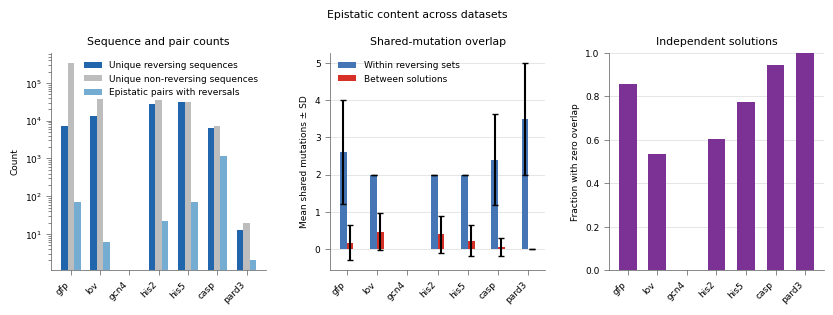

In [36]:

dataset_order = [
    "gfp", "lov", "gcn4", "nmt", "his2",
    "his5", "casp", "pte", "pard3",
]

fig, axes = plot_epistatic_content(
    epistasis_metrics_df,
    dataset_order=dataset_order,
    figsize=(8.2, 3),
    text_size=6.5,
    count_log_scale=True,
    bar_width=0.22,
    rotation=45,
    wspace=0.30,
)

export_plot("epistasis_difficulty_statistics")

plt.show()

In [37]:
epistasis_metrics_df

,dataset,unique_rescuers,common_rescuers,mean_intra_rescuers_distance,var_intra_rescuers,unique_solutions,mean_intra_unique,var_intra_unique,unique_non_rescuers
0,casp,"[4, 5, 6, 15, 17, 18, 21, 22, 23, 24, 27, 28, ...","[2, 2, 6, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, ...",2.400679,1.482920,0.945071,0.055845,0.054824,"[7, 8, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28,..."
1,gfp,"[1, 27, 58, 88, 110, 122, 132, 159, 172, 180, ...","[7, 3, 3, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...",2.608696,1.919345,0.854646,0.172634,0.221263,"[0, 1, 2, 4, 5, 6, 9, 10, 11, 12, 13, 14, 15, ..."
2,lov,"[199, 213, 214, 215, 256, 257, 258, 259, 260, ...","[2, 2, 2, 2, 2, 2]",2.000000,0.000000,0.533333,0.466667,0.248889,"[195, 196, 197, 198, 200, 201, 202, 203, 204, ..."
3,his2,"[1, 3, 4, 5, 7, 8, 9, 12, 13, 15, 16, 17, 20, ...","[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...",2.000000,0.000000,0.601732,0.398268,0.239651,"[2, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 16, 17,..."
4,his5,"[8, 12, 14, 16, 20, 21, 26, 27, 28, 29, 30, 33...","[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...",2.000000,0.000000,0.773843,0.226157,0.175010,"[1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 13, 15, 17, 1..."
5,gcn4,[],[],NaN,NaN,NaN,NaN,NaN,[]
6,pard3,"[716, 717, 718, 719, 720, 722, 724, 2574, 4614...","[2, 5]",3.500000,2.250000,1.000000,0.000000,0.000000,"[134, 173, 721, 723, 2542, 2547, 2599, 2602, 2..."


In [64]:


OUTPUT_COLUMNS = [
    "pair_identity",
    "epistasis_type",
    "is_epistatic",
    "dataset",
    "actual_fitness",
    "expected_pair_fitness",
    "pair_fitness",
    "additive_pair_fitness",
    "single_mutant_1_fitness",
    "single_mutant_2_fitness",
    "model",
]


def _verify_alignment(dataset, dataset_df, score_tables):
    for table_name, score_df in score_tables.items():
        if len(score_df) != len(dataset_df):
            raise ValueError(
                f"{dataset}: {table_name} has {len(score_df)} rows, but the dataset has "
                f"{len(dataset_df)} rows."
            )

        for sequence_column in ["full_seq", "seq_aa", "sequence", "seq"]:
            if sequence_column not in dataset_df or sequence_column not in score_df:
                continue

            dataset_sequences = dataset_df[sequence_column].fillna("").astype(str).to_numpy()
            score_sequences = score_df[sequence_column].fillna("").astype(str).to_numpy()

            if not np.array_equal(dataset_sequences, score_sequences):
                raise ValueError(
                    f"{dataset}: {table_name} row order does not match the dataset."
                )
            break


def _fitness_value(score_df, model, index, dataset, score_name):
    raw_value = float(score_df[model].iloc[index])
    return raw_value


def calculate_epistatic_pair_fitness(
    epi_df,
    fitness_root,
    models,
    datasets=None,
):
    """Return one row per epi_df pair and model."""
    models = [models] if isinstance(models, str) else list(models)

    if datasets is None:
        working_epi_df = epi_df.copy()
    else:
        datasets = [datasets] if isinstance(datasets, str) else list(datasets)
        working_epi_df = epi_df[epi_df["dataset"].isin(datasets)].copy()

    fitness_root = Path(fitness_root)
    records = []
    output_indices = []
    loaded_dataset = None

    for epi_index, pair_row in working_epi_df.iterrows():
        dataset = pair_row["dataset"]

        if dataset != loaded_dataset:
            dataset_info = datasets_and_activity[dataset]
            dataset_df = pd.read_csv(dataset_info["path"])
            activity_column = dataset_info["activity_col"]
            score_dir = fitness_root / dataset / "fitness_results"

            non_additive_fitness = pd.read_csv(score_dir / "pll_normed_fitness_all.csv")
            left_to_right_fitness = pd.read_csv(score_dir / "l2r_normed_fitness_all.csv")
            additive_fitness = pd.read_csv(score_dir / "new_om_normed_fitness_all.csv")

            non_additive_fitness["progen2-medium"] = (
                left_to_right_fitness["progen2-medium_left_to_right"]
            )
            non_additive_fitness["progen2-small"] = (
                left_to_right_fitness["progen2-small_left_to_right"]
            )

            _verify_alignment(
                dataset,
                dataset_df,
                {
                    "non-additive scores": non_additive_fitness,
                    "left-to-right scores": left_to_right_fitness,
                    "additive scores": additive_fitness,
                },
            )

            loaded_dataset = dataset

        pair_identity = pair_row["pair_identity"]
        pair_indices = pair_row["pair_indices"]

        if isinstance(pair_identity, str):
            pair_identity = ast.literal_eval(pair_identity)
        if isinstance(pair_indices, str):
            pair_indices = ast.literal_eval(pair_indices)

        pair_index = int(pair_indices[0])
        actual_fitness = float(dataset_df[activity_column].iloc[pair_index])

        mutation_1, mutation_2 = pair_identity
        mutation_1_column = mutation_1.split(":")[0]
        mutation_2_column = mutation_2.split(":")[0]
        mutation_1_aa = mutation_1.split(">")[-1]
        mutation_2_aa = mutation_2.split(">")[-1]

        single_mutant_1_index = np.where(
            (dataset_df[mutation_1_column] == mutation_1_aa)
            & (dataset_df["num_muts"] == 1)
        )[0].item()

        single_mutant_2_index = np.where(
            (dataset_df[mutation_2_column] == mutation_2_aa)
            & (dataset_df["num_muts"] == 1)
        )[0].item()

        for model in models:
            single_mutant_1_fitness = _fitness_value(
                non_additive_fitness,
                model,
                single_mutant_1_index,
                dataset,
                "single mutant 1",
            )
            single_mutant_2_fitness = _fitness_value(
                non_additive_fitness,
                model,
                single_mutant_2_index,
                dataset,
                "single mutant 2",
            )
            pair_fitness = _fitness_value(
                non_additive_fitness,
                model,
                pair_index,
                dataset,
                "pair",
            )
            additive_pair_fitness = _fitness_value(
                additive_fitness,
                model,
                pair_index,
                dataset,
                "additive pair",
            )

            records.append(
                {
                    "pair_identity": tuple(pair_identity),
                    "epistasis_type": pair_row["epistasis_type"],
                    "is_epistatic": pair_row["is_epistatic"],
                    "dataset": dataset,
                    "actual_fitness": actual_fitness,
                    "expected_pair_fitness": 0.5 * (single_mutant_1_fitness + single_mutant_2_fitness),
                    "pair_fitness": pair_fitness,
                    "additive_pair_fitness": additive_pair_fitness,
                    "single_mutant_1_fitness": single_mutant_1_fitness,
                    "single_mutant_2_fitness": single_mutant_2_fitness,
                    "model": model,
                }
            )
            output_indices.append(epi_index)

    result = pd.DataFrame(records, columns=OUTPUT_COLUMNS)
    result.index = pd.Index(output_indices, name=epi_df.index.name or "epi_index")
    return result

In [65]:
fitness_root = (
    "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/"
    "merged_datasets/epistasis_and_zs_analyses/zero_shot_scores"
)

models = [
    "esm_8m",
    "esm_35m",
    "esm_150m",
    "esm_650m",
    "esm_3b",
    "progen2-small",
    "progen2-medium",
    "saprot"
]

# IMPORTANT NOTE
# both expected and additive are additive
# expected is 1 mutation masked at a time across all mutations then averageed
# additive is all positions masked together (meaning that for each dataset)
# constantly we get the same number of masks and it is done in one forward pass
# non-additive is when only mutated positions get masked thus many forward passes


number_of_positives = ((epi_df["single_1_status"] == "positive").to_numpy().astype(int) + (epi_df["single_2_status"] == "positive").to_numpy().astype(int))

pair_fitness_df = calculate_epistatic_pair_fitness(
    epi_df=epi_df,
    fitness_root=fitness_root,
    datasets=["gfp", "casp", "his5", "his2", "pard3", "lov", "gfp"],
    models=models,
)

pair_fitness_df_no_amb = calculate_epistatic_pair_fitness(
    epi_df=epi_df[number_of_positives != 1],
    fitness_root=fitness_root,
    datasets=["gfp", "casp", "his5", "his2", "pard3", "lov", "gfp"],
    models=models,
)

In [40]:
# esm35mdf = pair_fitness_df[pair_fitness_df["model"] == "esm_3b"]
# is_epi = esm35mdf[esm35mdf["is_epistatic"]]
# is_not_epi = esm35mdf[esm35mdf["is_epistatic"] == False]


# import matplotlib.pyplot as plt
# import seaborn as sns

# box_one = (is_epi["expected_pair_fitness"] - is_epi["pair_fitness"]).abs()
# box_two = (is_not_epi["expected_pair_fitness"] - is_not_epi["pair_fitness"]).abs()

# # Combine data for boxplot
# plot_data = [
#     {"group": "Epistatic", "delta_fitness": val} for val in box_one
# ] + [
#     {"group": "Non-epistatic", "delta_fitness": val} for val in box_two
# ]
# plot_df = pd.DataFrame(plot_data)

# plt.figure(figsize=(6, 4))
# ax = sns.boxplot(data=plot_df, x="group", y="delta_fitness", showfliers=False)
# sns.stripplot(
#     data=plot_df, x="group", y="delta_fitness", 
#     color=".3", alpha=0.7, jitter=0.24, ax=ax
# )
# plt.ylabel("Expected - Actual Pair Fitness")
# plt.title("Epistatic vs. Non-epistatic Δ Fitness")
# plt.tight_layout()
# plt.show()

In [66]:
def plot_pair_delta_grouped_by_dataset(
    pair_fitness_df,
    models=None,
    dataset_order=None,
    delta_reference="expected",
    show_points=True,
    max_points_per_box=300,
    random_state=0,
    figsize=None,
    text_size=7,
    showfliers=False,
):
    """Plot all dataset/model pairs on one axis using min-max-normalized deltas."""
    reference_columns = {
        "expected": "expected_pair_fitness",
        "additive": "additive_pair_fitness",
    }

    if delta_reference not in reference_columns:
        raise ValueError("delta_reference must be 'expected' or 'additive'.")

    models = [models] if isinstance(models, str) else list(models)
    reference_column = reference_columns[delta_reference]

    required = {
        "dataset",
        "model",
        "is_epistatic",
        "pair_fitness",
        reference_column,
    }

    missing = required - set(pair_fitness_df.columns)

    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    data = pair_fitness_df[
        pair_fitness_df["model"].isin(models)
    ].copy()

    data["pair_fitness"] = pd.to_numeric(
        data["pair_fitness"],
        errors="coerce",
    )

    data[reference_column] = pd.to_numeric(
        data[reference_column],
        errors="coerce",
    )

    data["delta_raw"] = (
        data[reference_column] - data["pair_fitness"]
    ).abs()

    data = data[
        np.isfinite(data["delta_raw"])
        & data["is_epistatic"].notna()
    ]

    data["group"] = np.where(
        data["is_epistatic"].astype(bool),
        "Epistatic",
        "Non-epistatic",
    )

    if dataset_order is None:
        dataset_order = list(pd.unique(data["dataset"]))
    else:
        available = set(data["dataset"])

        dataset_order = [
            dataset
            for dataset in dataset_order
            if dataset in available
        ]

    if not dataset_order:
        raise ValueError("No rows match the requested models and datasets.")

    data = data[
        data["dataset"].isin(dataset_order)
    ].copy()

    grouped_delta = data.groupby(
        ["dataset", "model"]
    )["delta_raw"]

    delta_min = grouped_delta.transform("min")

    delta_range = (
        grouped_delta.transform("max")
        - delta_min
    )

    data["delta_fitness"] = np.where(
        delta_range > 0,
        (data["delta_raw"] - delta_min) / delta_range,
        0.0,
    )

    data["plot_key"] = (
        data["dataset"].astype(str)
        + " | "
        + data["model"].astype(str)
    )

    group_order = [
        "Epistatic",
        "Non-epistatic",
    ]

    group_colors = {
        "Epistatic": "#D55E00",
        "Non-epistatic": "#0072B2",
    }

    plot_order = []
    tick_labels = []
    dataset_centers = {}

    for dataset_index, dataset in enumerate(dataset_order):
        start = len(plot_order)

        for model in models:
            plot_order.append(f"{dataset} | {model}")
            tick_labels.append(model)

        dataset_centers[dataset] = (
            start + (len(models) - 1) / 2
        )

        if dataset_index < len(dataset_order) - 1:
            plot_order.append(f"__gap_{dataset_index}")
            tick_labels.append("")

    if figsize is None:
        figsize = (
            max(12, 0.72 * len(plot_order)),
            4.5,
        )

    fig, ax = plt.subplots(figsize=figsize)

    sns.boxplot(
        data=data,
        x="plot_key",
        y="delta_fitness",
        hue="group",
        order=plot_order,
        hue_order=group_order,
        palette=group_colors,
        width=0.62,
        showfliers=showfliers,
        ax=ax,
    )

    if show_points:
        point_parts = []

        for _, group in data.groupby(
            ["dataset", "model", "group"],
            sort=False,
        ):
            if (
                max_points_per_box is not None
                and len(group) > max_points_per_box
            ):
                group = group.sample(
                    max_points_per_box,
                    random_state=random_state,
                )

            point_parts.append(group)

        if point_parts:
            point_data = pd.concat(
                point_parts,
                ignore_index=True,
            )

            sns.stripplot(
                data=point_data,
                x="plot_key",
                y="delta_fitness",
                hue="group",
                order=plot_order,
                hue_order=group_order,
                palette=group_colors,
                dodge=True,
                jitter=0.22,
                size=2,
                alpha=0.55,
                legend=False,
                ax=ax,
            )

    legend = ax.get_legend()

    if legend is not None:
        legend.remove()

    ax.set_xticks(range(len(plot_order)))
    ax.set_xticklabels(
        tick_labels,
        rotation=35,
        ha="right",
    )

    for dataset, center in dataset_centers.items():
        ax.text(
            center,
            1.08,
            dataset,
            ha="center",
            va="center",
            fontsize=text_size,
            fontweight="bold",
        )

    reference_label = (
        "Expected"
        if delta_reference == "expected"
        else "Additive"
    )

    ax.set_xlabel("")
    ax.set_ylabel(
        f"|Non-additive - Additive fitness| (Min-Max)"
    )

    ax.set_ylim(-0.02, 1.15)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

    fig.legend(
        handles=[
            Patch(
                facecolor=group_colors[group],
                label=group,
            )
            for group in group_order
        ],
        loc="upper center",
        ncol=2,
        frameon=False,
    )

    fig.tight_layout(
        rect=(0.02, 0.14, 1, 0.92)
    )

    for text in fig.findobj(plt.Text):
        text.set_fontsize(text_size)

    return fig, ax

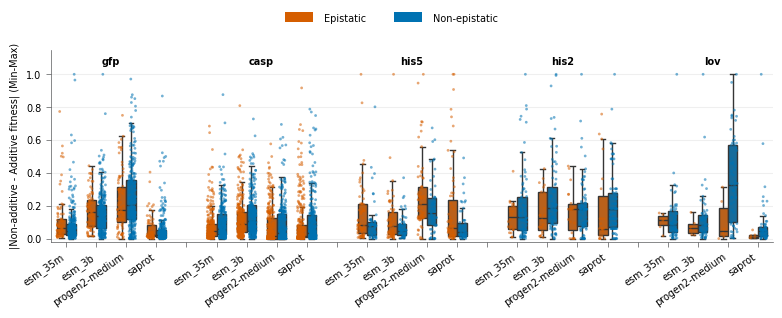

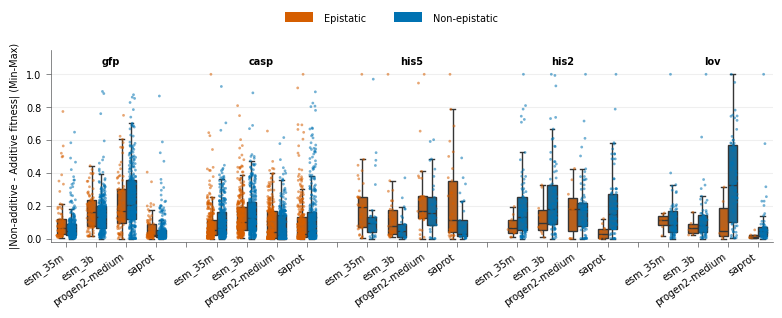

In [67]:
# IMPORTANT NOTE
# both expected and additive are additive
# expected is 1 mutation masked at a time across all mutations then averageed
# additive is all positions masked together (meaning that for each dataset)
# constantly we get the same number of masks and it is done in one forward pass
# non-additive is when only mutated positions get masked thus many forward passes


#no_intermediate_epistasis = ["no_epistasis_expected_negative", "no_epistasis_expected_positive", "strong_positive_sign_epistasis", "negative_sign_epistasis"]

fig, ax = plot_pair_delta_grouped_by_dataset(
    pair_fitness_df,
    models=["esm_35m", "esm_3b", "progen2-medium", "saprot"],
    dataset_order=["gfp", "casp", "his5", "his2", "lov"],
    delta_reference="expected",  
    show_points=True,
    max_points_per_box=300,
    random_state=0,
    figsize=(8.2, 4),
    text_size=7,
    showfliers=False,
)

export_plot("epistasis_classification_raw_fitness")

fig, ax = plot_pair_delta_grouped_by_dataset(
    pair_fitness_df_no_amb,
    models=["esm_35m", "esm_3b", "progen2-medium", "saprot"],
    dataset_order=["gfp", "casp", "his5", "his2", "lov"],
    delta_reference="expected",  
    show_points=True,
    max_points_per_box=300,
    random_state=0,
    figsize=(8.2, 4),
    text_size=7,
    showfliers=False,
)

export_plot("epistasis_classification_raw_fitness_just_strong_and_neg")

#LOV and his 2 are spurious at this point

plt.show()

In [68]:
pair_fitness_df

,pair_identity,epistasis_type,is_epistatic,dataset,actual_fitness,expected_pair_fitness,pair_fitness,additive_pair_fitness,single_mutant_1_fitness,single_mutant_2_fitness,model
epi_index,,,,,,,,,,,
0,"(A572:A>C, G586:G>P)",no_epistasis_expected_negative,False,casp,-0.204256,-1.925682,-1.874901,-1.912010,-3.553833,-0.297531,esm_8m
0,"(A572:A>C, G586:G>P)",no_epistasis_expected_negative,False,casp,-0.204256,-1.157211,-1.174789,-1.147446,-2.370667,0.056244,esm_35m
0,"(A572:A>C, G586:G>P)",no_epistasis_expected_negative,False,casp,-0.204256,-0.993744,-1.006989,-1.004944,-2.113190,0.125702,esm_150m
0,"(A572:A>C, G586:G>P)",no_epistasis_expected_negative,False,casp,-0.204256,-1.020214,-1.034863,-1.023144,-2.014526,-0.025902,esm_650m
0,"(A572:A>C, G586:G>P)",no_epistasis_expected_negative,False,casp,-0.204256,-1.020731,-0.997293,-1.018290,-2.135453,0.093990,esm_3b
...,...,...,...,...,...,...,...,...,...,...,...
4165,"(L42:L>V, S72:S>V)",no_epistasis_expected_positive,False,gfp,0.000000,-0.030174,0.007423,-0.026268,0.020790,-0.081139,esm_650m
4165,"(L42:L>V, S72:S>V)",no_epistasis_expected_positive,False,gfp,0.000000,-0.011765,-0.041794,-0.017624,-0.013748,-0.009781,esm_3b
4165,"(L42:L>V, S72:S>V)",no_epistasis_expected_positive,False,gfp,0.000000,-0.693802,-0.466240,0.000000,0.096458,-1.484062,progen2-small


In [44]:
pair_fitness_df["epistasis_type"].unique()

array(['no_epistasis_expected_negative', 'weak_positive_sign_epistasis',
       'strong_positive_sign_epistasis', 'no_epistasis_expected_positive',
       'negative_sign_epistasis'], dtype=object)

In [45]:
pair_fitness_df

,pair_identity,epistasis_type,is_epistatic,dataset,actual_fitness,expected_pair_fitness,pair_fitness,additive_pair_fitness,single_mutant_1_fitness,single_mutant_2_fitness,model
epi_index,,,,,,,,,,,
0,"(A572:A>C, G586:G>P)",no_epistasis_expected_negative,False,casp,-0.204256,-1.925682,-3.749802,-2.601414,-3.553833,-0.297531,esm_8m
0,"(A572:A>C, G586:G>P)",no_epistasis_expected_negative,False,casp,-0.204256,-1.157211,-2.349579,-2.200627,-2.370667,0.056244,esm_35m
0,"(A572:A>C, G586:G>P)",no_epistasis_expected_negative,False,casp,-0.204256,-0.993744,-2.013977,-1.862868,-2.113190,0.125702,esm_150m
0,"(A572:A>C, G586:G>P)",no_epistasis_expected_negative,False,casp,-0.204256,-1.020214,-2.069725,-3.726869,-2.014526,-0.025902,esm_650m
0,"(A572:A>C, G586:G>P)",no_epistasis_expected_negative,False,casp,-0.204256,-1.020731,-1.994587,-3.745000,-2.135452,0.093990,esm_3b
...,...,...,...,...,...,...,...,...,...,...,...
4165,"(L42:L>V, S72:S>V)",no_epistasis_expected_positive,False,gfp,0.000000,-0.030174,0.014847,-0.141500,0.020790,-0.081139,esm_650m
4165,"(L42:L>V, S72:S>V)",no_epistasis_expected_positive,False,gfp,0.000000,-0.011765,-0.083588,-0.225574,-0.013748,-0.009781,esm_3b
4165,"(L42:L>V, S72:S>V)",no_epistasis_expected_positive,False,gfp,0.000000,-0.693802,-0.932480,-0.716271,0.096458,-1.484062,progen2-small


In [46]:
def plot_pair_delta_auc_bars_by_dataset(
    pair_fitness_df,
    models=("esm_35m", "esm_3b", "progen2-medium"),
    dataset_order=None,
    delta_reference="expected",
    positive_group="epistatic",
    figsize=None,
    text_size=7,
    bar_width=0.62,
):
    """Plot AUC values and epistatic-pair rates by dataset and model."""
    reference_columns = {
        "expected": "expected_pair_fitness",
        "additive": "additive_pair_fitness",
    }

    if delta_reference not in reference_columns:
        raise ValueError("delta_reference must be 'expected' or 'additive'.")

    positive_group = positive_group.lower().replace("-", "_")

    if positive_group not in {"epistatic", "non_epistatic"}:
        raise ValueError("positive_group must be 'epistatic' or 'non_epistatic'.")

    models = [models] if isinstance(models, str) else list(models)
    reference_column = reference_columns[delta_reference]

    required = {
        "dataset",
        "model",
        "is_epistatic",
        "pair_fitness",
        reference_column,
    }

    missing = required - set(pair_fitness_df.columns)

    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    data = pair_fitness_df[
        pair_fitness_df["model"].isin(models)
    ].copy()

    data["pair_fitness"] = pd.to_numeric(
        data["pair_fitness"],
        errors="coerce",
    )

    data[reference_column] = pd.to_numeric(
        data[reference_column],
        errors="coerce",
    )

    data["delta_raw"] = (
        data[reference_column] - data["pair_fitness"]
    ).abs()

    data = data[
        np.isfinite(data["delta_raw"])
        & data["is_epistatic"].notna()
    ]

    if dataset_order is None:
        dataset_order = list(pd.unique(data["dataset"]))
    else:
        available = set(data["dataset"])

        dataset_order = [
            dataset
            for dataset in dataset_order
            if dataset in available
        ]

    if not dataset_order:
        raise ValueError("No rows match the requested models and datasets.")

    positive_is_epistatic = positive_group == "epistatic"
    auc_rows = []

    for dataset in dataset_order:
        for model in models:
            model_data = data[
                (data["dataset"] == dataset)
                & (data["model"] == model)
            ]

            if model_data.empty:
                continue

            is_epistatic = model_data["is_epistatic"].astype(bool)

            auc_rows.append({
                "dataset": dataset,
                "model": model,
                "metric": "Epistatic pairs",
                "value": is_epistatic.mean(),
            })

            labels = (
                is_epistatic
                .eq(positive_is_epistatic)
                .astype(int)
            )

            if labels.nunique() < 2:
                continue

            scores = model_data["delta_raw"]

            auc_rows.extend([
                {
                    "dataset": dataset,
                    "model": model,
                    "metric": "ROC-AUC",
                    "value": roc_auc_score(labels, scores),
                },
                {
                    "dataset": dataset,
                    "model": model,
                    "metric": "PR-AUC",
                    "value": average_precision_score(labels, scores),
                },
            ])

    auc_df = pd.DataFrame(auc_rows)

    if auc_df.empty:
        raise ValueError(
            "No valid rows match the requested datasets and models."
        )

    auc_df["plot_key"] = (
        auc_df["dataset"].astype(str)
        + " | "
        + auc_df["model"].astype(str)
    )

    plot_order = []
    tick_labels = []
    dataset_centers = {}

    for dataset_index, dataset in enumerate(dataset_order):
        start = len(plot_order)

        for model in models:
            plot_order.append(f"{dataset} | {model}")
            tick_labels.append(model)

        dataset_centers[dataset] = (
            start + (len(models) - 1) / 2
        )

        if dataset_index < len(dataset_order) - 1:
            plot_order.append(f"__gap_{dataset_index}")
            tick_labels.append("")

    if figsize is None:
        figsize = (
            max(12, 0.72 * len(plot_order)),
            4.2,
        )

    fig, ax = plt.subplots(figsize=figsize)

    metric_order = [
        "ROC-AUC",
        "PR-AUC",
        "Epistatic pairs",
    ]

    metric_palette = {
        "ROC-AUC": "#0072B2",
        "PR-AUC": "#D55E00",
        "Epistatic pairs": "#54A24B",
    }

    sns.barplot(
        data=auc_df,
        x="plot_key",
        y="value",
        hue="metric",
        order=plot_order,
        hue_order=metric_order,
        palette=metric_palette,
        width=bar_width,
        errorbar=None,
        ax=ax,
    )

    ax.set_xticks(range(len(plot_order)))
    ax.set_xticklabels(
        tick_labels,
        rotation=35,
        ha="right",
    )

    for dataset, center in dataset_centers.items():
        ax.text(
            center,
            1.06,
            dataset,
            ha="center",
            va="center",
            fontsize=text_size,
            fontweight="bold",
        )

    ax.set_xlabel("")
    ax.set_ylabel("Value (%)")
    ax.set_ylim(0, 1.12)

    ax.yaxis.set_major_formatter(
        PercentFormatter(xmax=1)
    )

    ax.axhline(
        0.5,
        color="black",
        linestyle="--",
        linewidth=0.8,
        zorder=0,
    )

    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=3,
        frameon=False,
    )

    fig.tight_layout(
        rect=(0.02, 0.14, 1, 0.92)
    )

    for text in fig.findobj(plt.Text):
        text.set_fontsize(text_size)

    return fig, ax

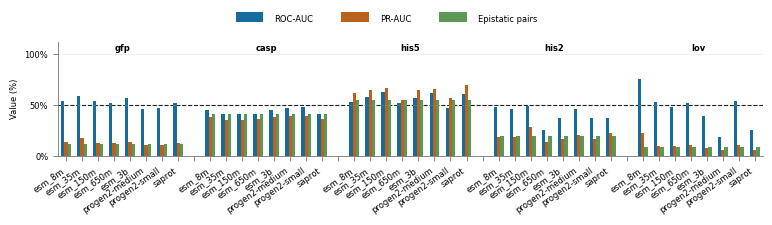

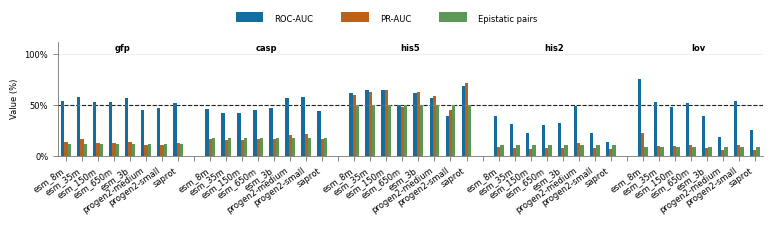

In [69]:
# IMPORTANT NOTE
# both expected and additive are additive
# expected is 1 mutation masked at a time across all mutations then averageed
# additive is all positions masked together (meaning that for each dataset)
# constantly we get the same number of masks and it is done in one forward pass
# non-additive is when only mutated positions get masked thus many forward passes

fig, ax = plot_pair_delta_auc_bars_by_dataset(
    pair_fitness_df,
    models=["esm_8m", "esm_35m", "esm_150m", "esm_650m", "esm_3b", "progen2-medium", "progen2-small", "saprot"],
    dataset_order=["gfp", "casp", "his5", "his2", "lov"],
    delta_reference="expected",  # or "additive"
    positive_group="epistatic",
    figsize=(8.2, 3),
    text_size=6,
    bar_width=0.62,
)

export_plot("epistasis_classification_roc_auc")

fig, ax = plot_pair_delta_auc_bars_by_dataset(
    pair_fitness_df_no_amb,
    models=["esm_8m", "esm_35m", "esm_150m", "esm_650m", "esm_3b", "progen2-medium", "progen2-small", "saprot"],
    dataset_order=["gfp", "casp", "his5", "his2", "lov"],
    delta_reference="expected",  # or "additive"
    positive_group="epistatic",
    figsize=(8.2, 3),
    text_size=6,
    bar_width=0.62,
)

export_plot("epistasis_classification_roc_auc_just_strong_and_neg")

plt.show()

In [71]:
def plot_epistatic_fitness_correlations(
    fitness_df,
    models=None,
    dataset_order=None,
    figsize=None,
    text_size=7,
    bar_width=0.62,
):
    """Plot pair or high-order reverser fitness correlations."""
    # calculate_high_order_reverser_fitness returns (fitness_df, count_df).
    if isinstance(fitness_df, tuple):
        fitness_df = fitness_df[0]

    pair_columns = {
        "is_epistatic",
        "pair_fitness",
        "expected_pair_fitness",
    }

    high_order_columns = {
        "non_additive_fitness",
        "expected_fitness",
    }

    if pair_columns <= set(fitness_df.columns):
        data = fitness_df[fitness_df["is_epistatic"] == True].copy()

        comparisons = {
            "Non-additive fitness": "pair_fitness",
            "Additive fitness": "expected_pair_fitness",
        }

    elif high_order_columns <= set(fitness_df.columns):
        data = fitness_df.copy()

        comparisons = {
            "Non-additive fitness": "non_additive_fitness",
            "Additive fitness": "expected_fitness",
        }

    else:
        raise ValueError(
            "The dataframe does not match the pair or high-order reverser schema."
        )

    colors = {
        "Non-additive fitness": "#3665A7",
        "Additive fitness": "#BDBDBD",
    }

    required = {
        "dataset",
        "model",
        "actual_fitness",
        *comparisons.values(),
    }

    missing = required - set(data.columns)

    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    if models is None:
        models = list(pd.unique(data["model"]))
    else:
        models = [models] if isinstance(models, str) else list(models)

    data = data[data["model"].isin(models)]

    if dataset_order is None:
        dataset_order = list(pd.unique(data["dataset"]))
    else:
        available = set(data["dataset"])
        dataset_order = [
            dataset
            for dataset in dataset_order
            if dataset in available
        ]

    for column in ["actual_fitness", *comparisons.values()]:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    correlation_rows = []

    for dataset in dataset_order:
        for model in models:
            model_data = data[
                (data["dataset"] == dataset)
                & (data["model"] == model)
            ]

            for comparison, predicted_column in comparisons.items():
                values = model_data[
                    ["actual_fitness", predicted_column]
                ].dropna()

                if (
                    len(values) < 2
                    or values["actual_fitness"].nunique() < 2
                    or values[predicted_column].nunique() < 2
                ):
                    continue

                correlation, _ = spearmanr(
                    values["actual_fitness"],
                    values[predicted_column],
                )

                if np.isfinite(correlation) and correlation != 0:
                    correlation_rows.append({
                        "dataset": dataset,
                        "model": model,
                        "comparison": comparison,
                        "correlation": abs(correlation),
                    })

    correlation_df = pd.DataFrame(correlation_rows)

    if correlation_df.empty:
        raise ValueError(
            "No nonzero Spearman correlations could be calculated."
        )

    correlation_df["plot_key"] = (
        correlation_df["dataset"].astype(str)
        + " | "
        + correlation_df["model"].astype(str)
    )

    plot_order = []
    tick_labels = []
    dataset_centers = {}

    for dataset_index, dataset in enumerate(dataset_order):
        start = len(plot_order)

        for model in models:
            plot_order.append(f"{dataset} | {model}")
            tick_labels.append(model)

        dataset_centers[dataset] = (
            start + (len(models) - 1) / 2
        )

        if dataset_index < len(dataset_order) - 1:
            plot_order.append(f"__gap_{dataset_index}")
            tick_labels.append("")

    if figsize is None:
        figsize = (
            max(12, 0.72 * len(plot_order)),
            4.2,
        )

    fig, ax = plt.subplots(figsize=figsize)

    sns.barplot(
        data=correlation_df,
        x="plot_key",
        y="correlation",
        hue="comparison",
        order=plot_order,
        hue_order=list(comparisons),
        palette=colors,
        width=bar_width,
        errorbar=None,
        ax=ax,
    )

    ax.set_xticks(range(len(plot_order)))
    ax.set_xticklabels(
        tick_labels,
        rotation=35,
        ha="right",
    )

    for dataset, center in dataset_centers.items():
        ax.text(
            center,
            1.04,
            dataset,
            ha="center",
            va="center",
            fontsize=text_size,
            fontweight="bold",
        )

    minimum_correlation = correlation_df["correlation"].min()
    lower_limit = 10 ** np.floor(np.log10(minimum_correlation))

    ax.set_yscale("log")
    ax.set_ylim(lower_limit, 1.1)

    ax.set_xlabel("")
    ax.set_ylabel("|Spearman correlation| (log scale)")

    # ax.grid(
    #     axis="y",
    #     which="both",
    #     alpha=0.2,
    # )

    ax.spines[["top", "right"]].set_visible(False)

    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=2,
        frameon=False,
    )

    fig.tight_layout(
        rect=(0.02, 0.14, 1, 0.92)
    )

    for text in fig.findobj(plt.Text):
        text.set_fontsize(text_size)

    return fig, ax

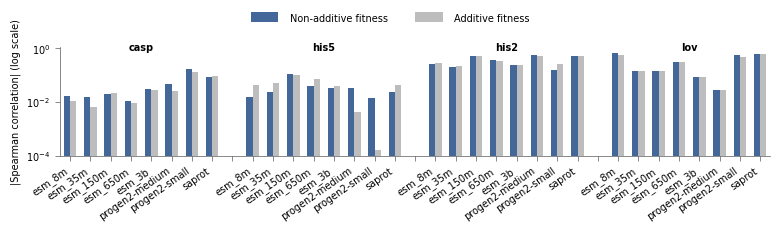

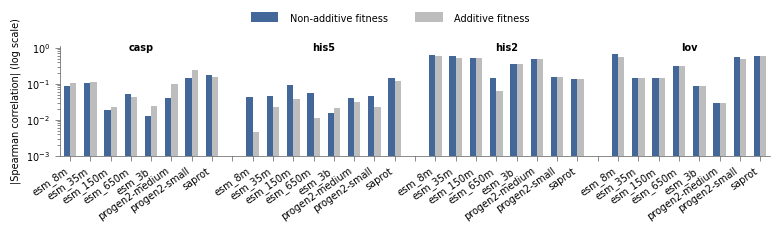

In [72]:

# IMPORTANT NOTE
# both expected and additive are additive
# expected is 1 mutation masked at a time across all mutations then averageed
# additive is all positions masked together (meaning that for each dataset)
# constantly we get the same number of masks and it is done in one forward pass
# non-additive is when only mutated positions get masked thus many forward passes


fig, ax = plot_epistatic_fitness_correlations(
    pair_fitness_df,
    models=["esm_8m", "esm_35m", "esm_150m", "esm_650m", "esm_3b", "progen2-medium", "progen2-small", "saprot"],
    dataset_order=["casp", "his5", "his2", "lov"],
    figsize=(8.2, 3),
    text_size=7,
    bar_width=0.62,
)

export_plot("epistasis_analysis_additive_vs_non_additive_in_pairs")

plt.show()


fig, ax = plot_epistatic_fitness_correlations(
    pair_fitness_df_no_amb,#[pair_fitness_df["epistasis_type"] != "weak_positive_sign_epistasis"],
    models=["esm_8m", "esm_35m", "esm_150m", "esm_650m", "esm_3b", "progen2-medium", "progen2-small", "saprot"],
    dataset_order=["casp", "his5", "his2", "lov"],
    figsize=(8.2, 3),
    text_size=7,
    bar_width=0.62,
)

export_plot("epistasis_analysis_additive_vs_non_additive_in_pairs_just_strong_and_neg")

plt.show()

In [78]:

def calculate_high_order_reverser_fitness(
    reverser_df,
    fitness_root,
    models,
    max_n=None,
    random_state=0,
):
    """Calculate model fitnesses for unique, findable high-order reversers."""
    models = [models] if isinstance(models, str) else list(models)
    fitness_root = Path(fitness_root)
    rng = np.random.default_rng(random_state)
    records = []
    count_records = []

    for dataset in reverser_df["dataset"].drop_duplicates():
        dataset_info = datasets_and_activity[dataset]
        dataset_df = pd.read_csv(dataset_info["path"])
        activity_column = dataset_info["activity_col"]
        score_dir = fitness_root / dataset / "fitness_results"

        non_additive_fitness = pd.read_csv(score_dir / "pll_normed_fitness_all.csv")
        left_to_right_fitness = pd.read_csv(score_dir / "l2r_normed_fitness_all.csv")
        additive_fitness = pd.read_csv(score_dir / "new_om_normed_fitness_all.csv")

        non_additive_fitness["progen2-medium"] = (
            left_to_right_fitness["progen2-medium_left_to_right"]
        )
        non_additive_fitness["progen2-small"] = (
            left_to_right_fitness["progen2-small_left_to_right"]
        )

        _verify_alignment(
            dataset,
            dataset_df,
            {
                "non-additive scores": non_additive_fitness,
                "left-to-right scores": left_to_right_fitness,
                "additive scores": additive_fitness,
            },
        )

        all_reverser_indices = []
        for indices in reverser_df.loc[
            reverser_df["dataset"] == dataset, "unique_rescuers"
        ]:
            if isinstance(indices, str):
                indices = ast.literal_eval(indices)
            all_reverser_indices.extend(indices)

        unique_reversers = np.unique(all_reverser_indices).astype(int)
        relevant_columns = get_relevant_columns(dataset, dataset_df)
        wt_row = dataset_df[dataset_df["num_muts"] == 0].iloc[0]
        findable_reversers = {}

        for reverser_index in unique_reversers:
            reverser_row = dataset_df.iloc[reverser_index]
            mutated_columns = [
                column
                for column in relevant_columns
                if reverser_row[column] != wt_row[column]
            ]

            single_mutant_indices = []
            all_singles_exist = True

            for column in mutated_columns:
                mutant_aa = reverser_row[column]
                single_indices = np.where(
                    (dataset_df[column] == mutant_aa) & (dataset_df["num_muts"] == 1)
                )[0]

                if len(single_indices) != 1:
                    all_singles_exist = False
                    break

                single_mutant_indices.append(int(single_indices[0]))

            if all_singles_exist and single_mutant_indices:
                reverser_identity = tuple(
                    f"{column}:{wt_row[column]}>{reverser_row[column]}"
                    for column in mutated_columns
                )
                findable_reversers[int(reverser_index)] = (
                    single_mutant_indices,
                    reverser_identity,
                )

        findable_indices = np.array(list(findable_reversers), dtype=int)
        if max_n is not None and len(findable_indices) > max_n:
            sampled_indices = np.sort(rng.choice(findable_indices, size=max_n, replace=False))
        else:
            sampled_indices = findable_indices

        count_records.append(
            {
                "dataset": dataset,
                "n_unique_reversers": len(unique_reversers),
                "n_findable_reversers": len(findable_indices),
                "n_sampled_reversers": len(sampled_indices),
            }
        )

        for reverser_index in sampled_indices:
            single_indices, reverser_identity = findable_reversers[reverser_index]
            actual_fitness = float(dataset_df[activity_column].iloc[reverser_index])
            num_muts = int(dataset_df["num_muts"].iloc[reverser_index])

            for model in models:
                single_fitnesses = [
                    _fitness_value(
                        non_additive_fitness,
                        model,
                        single_index,
                        dataset,
                        "single mutant",
                    )
                    for single_index in single_indices
                ]

                records.append(
                    {
                        "dataset": dataset,
                        "reverser_index": int(reverser_index),
                        "reverser_identity": reverser_identity,
                        "num_muts": num_muts,
                        "actual_fitness": actual_fitness,
                        "expected_fitness": float(np.mean(single_fitnesses)),
                        "additive_fitness": _fitness_value(
                            additive_fitness,
                            model,
                            reverser_index,
                            dataset,
                            "additive fitness",
                        ),
                        "non_additive_fitness": _fitness_value(
                            non_additive_fitness,
                            model,
                            reverser_index,
                            dataset,
                            "non-additive fitness",
                        ),
                        "model": model,
                    }
                )

    fitness_columns = [
        "dataset",
        "reverser_index",
        "reverser_identity",
        "num_muts",
        "actual_fitness",
        "expected_fitness",
        "additive_fitness",
        "non_additive_fitness",
        "model",
    ]
    count_columns = [
        "dataset",
        "n_unique_reversers",
        "n_findable_reversers",
        "n_sampled_reversers",
    ]

    return (
        pd.DataFrame(records, columns=fitness_columns),
        pd.DataFrame(count_records, columns=count_columns),
    )

In [ ]:
create = False
df_path = "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/epistasis_and_zs_analyses/reversers_epi.csv"
if create:
    high_order_epi_df = calculate_high_order_reverser_fitness(
        reverser_df=epistasis_metrics_df,
        fitness_root=fitness_root,
        #datasets=["gfp", "casp", "his5", "his2", "pard3", "lov", "gfp"],
        models=models,
    )
    high_order_epi_df[0].to_csv(df_path)
else:
    high_order_epi_df = pd.read_csv(df_path)

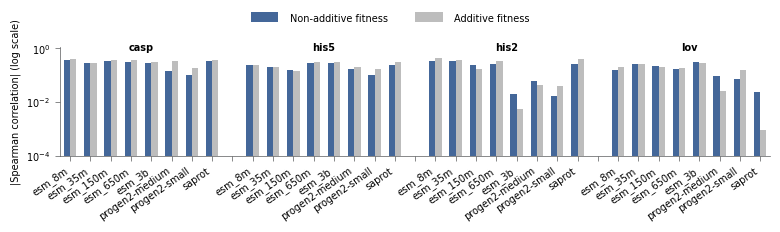

In [80]:
fig, ax = plot_epistatic_fitness_correlations(
    high_order_epi_df,
    models=["esm_8m", "esm_35m", "esm_150m", "esm_650m", "esm_3b", "progen2-medium", "progen2-small", "saprot"],
    dataset_order=["casp", "his5", "his2", "lov"],
    figsize=(8.2, 3),
    text_size=7,
    bar_width=0.62,
)

export_plot("epistasis_analysis_additive_vs_non_additive_in_all")

plt.show()

In [53]:
# non_additive_gfp_ftns = pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/epistasis_and_zs_analyses/zero_shot_scores/gfp/fitness_results/pll_fitness_all.csv")
# l2r_gfp_ftns =pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/epistasis_and_zs_analyses/zero_shot_scores/gfp/fitness_results/l2r_fitness_all.csv")
# additive_gfp_ftns = pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/epistasis_and_zs_analyses/zero_shot_scores/gfp/fitness_results/fitness_all.csv")
# non_additive_gfp_ftns["progen2-medium"] = l2r_gfp_ftns["progen2-medium_left_to_right"]
# non_additive_gfp_ftns["progen2-small"] = l2r_gfp_ftns["progen2-small_left_to_right"]

# df = pd.read_csv(DATASET_PATHS["gfp"])

# work_pair = epi_df[epi_df["dataset"] == "gfp"].iloc[2]
# work_pair

# work_pair["pair_identity"]

# pair_ind = work_pair["pair_indices"]
# pair_ind = int(pair_ind[1:-1])
# mutant_1_ind = np.where((df["L42"] == "I") & (df["num_muts"] == 1))[0]
# mutant_2_ind = np.where((df["Q94"] == "L") & (df["num_muts"] == 1))[0]

# single_mutant_1_fitness = non_additive_gfp_ftns["esm_35m"].iloc[mutant_1_ind]
# single_mutant_2_fitness = non_additive_gfp_ftns["esm_35m"].iloc[mutant_2_ind]
# pair_fitness = non_additive_gfp_ftns["esm_35m"].iloc[pair_ind]
# additive_pair_fitness = additive_gfp_ftns["esm_35m"].iloc[pair_ind]

# expected_fitness = 0.5 * (single_mutant_1_fitness.item() + single_mutant_2_fitness.item())
# actual_fitness = pair_fitness
# expected_fitness



In [54]:


# common_ancestor_size = []
# variance = []
# mean_dist = []
# for epistatic_ind in np.where(rescue_mut_order_df.sum(axis=1) > 0)[0]:
#     rescue_indices = [
#         idx
#         for indices in working_epi_df.loc[
#             working_epi_df["is_epistatic"],
#             "reverse_indices"
#         ].iloc[epistatic_ind].values()
#         for idx in indices
#     ]
#     # print(gfpepi[gfpepi["is_epistatic"]].iloc[1])

#     ind_of_int = np.array(rescue_indices)
#     muts_only_mt = (ohe[ind_of_int] - (ohe[ind_of_int] & ohe[wt_ind]))
#     dist_mat = (muts_only_mt @ muts_only_mt.T)
#     lower_triangle = np.tril(dist_mat)
#     common_ancestor_size.append(dist_mat.min())
#     variance.append(lower_triangle.var())
#     mean_dist.append(lower_triangle.mean())

In [55]:
# sns.heatmap((muts_only_mt @ muts_only_mt.T))

In [56]:
# import numpy as np
# import seaborn as sns
# import matplotlib.pyplot as plt

# epi_df_plot = pd.concat(epistasis_across)
# #epi_df_plot["abs_experimental_epistasis"] = np.log(np.abs(epi_df_plot["experimental_epistasis"])) 

# summary = (
#     epi_df_plot
#     .groupby("dataset")
#     .agg(
#         n_variants=("single_additive_epistasis", "size"),
#         mean_signed_epistasis=("single_additive_epistasis", "mean"),
#         median_abs_epistasis=("single_additive_epistasis", lambda x: np.median(np.abs(x))),
#         rms_epistasis=("single_additive_epistasis", lambda x: np.sqrt(np.mean(x**2))),
#         epistasis_sd=("single_additive_epistasis", "std"),
#         y_sd=("y_observed", "std"),
#     )
#     .reset_index()
# )

# summary["relative_epistasis_sd"] = summary["epistasis_sd"] / summary["y_sd"]
# summary["relative_rms_epistasis"] = summary["rms_epistasis"] / summary["y_sd"]

# summary

# plt.figure(figsize=(8, 4))

# sns.barplot(
#     data=summary,
#     x="dataset",
#     y="median_abs_epistasis"
# )

# plt.ylabel("RMS epistasis / phenotype SD")
# plt.xlabel("Dataset")
# plt.xticks(rotation=45, ha="right")
# plt.tight_layout()
# plt.show()

In [57]:
# epi_df_plot

In [58]:
# import numpy as np
# import pandas as pd

# import seaborn as sns
# import matplotlib.pyplot as plt

# from scipy import sparse
# from sklearn.linear_model import LogisticRegression
# from sklearn.neural_network import MLPClassifier
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler

# from sklearn.exceptions import ConvergenceWarning

# import warnings
# warnings.filterwarnings("ignore", category=ConvergenceWarning)


# def compute_metrics(y_true, score, k_precision=100):
#     y_true = np.asarray(y_true).astype(int)

#     if len(np.unique(y_true)) < 2:
#         return {
#             "auc": np.nan,
#             "average_precision": np.nan,
#             "precision_at_k": np.nan,
#             "k": np.nan,
#             "positive_rate_test": y_true.mean()
#         }

#     auc = roc_auc_score(y_true, score)
#     ap = average_precision_score(y_true, score)

#     k = min(k_precision, len(y_true))
#     top_idx = np.argsort(score)[::-1][:k]
#     precision_at_k = y_true[top_idx].mean()

#     return {
#         "auc": auc,
#         "average_precision": ap,
#         "precision_at_k": precision_at_k,
#         "k": k,
#         "positive_rate_test": y_true.mean()
#     }


# def sample_train_indices(candidate_idx, y, fraction, n_repeats=100, seed=0):
#     """
#     Samples a fraction of candidate_idx.
#     For fraction == 1.0, returns exactly one sample containing all candidates.
#     """
#     rng = np.random.default_rng(seed)
#     candidate_idx = np.asarray(candidate_idx)
#     y_candidate = np.asarray(y)[candidate_idx]

#     if fraction == 1.0:
#         if len(np.unique(y_candidate)) < 2:
#             return []
#         return [(0, candidate_idx)]

#     n_candidates = len(candidate_idx)
#     n_train = int(round(fraction * n_candidates))
#     n_train = max(n_train, 2)

#     samples = []

#     for rep in range(n_repeats):
#         sampled = rng.choice(candidate_idx, size=n_train, replace=False)

#         # Need both classes for classifier training
#         if len(np.unique(y[sampled])) < 2:
#             continue

#         samples.append((rep, sampled))

#     return samples


# def run_order_extrapolation_experiment(
#     datasets,
#     train_order_thresholds=(1, 2, 3),
#     train_fractions=(0.25, 0.50, 0.75, 1.00),
#     test_orders=(4, 5, 6, 7),
#     n_repeats=100,
#     k_precision=100,
#     random_seed=0
# ):
#     all_rows = []

#     for dataset_name in datasets:
#         print(f"\nWorking on {dataset_name}")

#         #dataset = "gfp"
#         dataset_path = DATASET_PATHS[dataset_name]
#         df = pd.read_csv(dataset_path)
#         wt_seq = df[df["num_muts"] == 0]["full_seq"].iloc[0]
#         df = df[(df["num_muts"] >= 1) & (df["num_muts"] <= 10)]
        
#         # get one-hot encoding for relevant columns
#         relevant_columns = get_relevant_columns(dataset_name, df)
#         ohe = get_one_hot_encoding(df, relevant_columns)
#         ohe_columns = ohe.columns
#         X = ohe.to_numpy().astype(int)

#         mut_order = df["num_muts"].to_numpy()
#         if dataset_name == "gfp":
#                 activity = 1 - df["inactive"]
#                 y = activity
#         else:
#             activity = df[datasets_and_activity[dataset_name]["activity_col"]]
#             y = (activity > np.quantile(activity, 0.9)).astype(int)

#         if hasattr(X, "values"):
#             X = X.values

#         if not sparse.issparse(X):
#             X = sparse.csr_matrix(X)
#         else:
#             X = X.tocsr()

#         for max_train_order in train_order_thresholds:
#             candidate_train_idx = np.where(mut_order <= max_train_order)[0]

#             print(
#                 f"  Train candidates <= {max_train_order} muts: "
#                 f"{len(candidate_train_idx)}"
#             )

#             if len(candidate_train_idx) == 0:
#                 continue

#             for train_fraction in train_fractions:
#                 train_samples = sample_train_indices(
#                     candidate_idx=candidate_train_idx,
#                     y=y,
#                     fraction=train_fraction,
#                     n_repeats=n_repeats,
#                     seed=random_seed + max_train_order * 1000 + int(train_fraction * 100)
#                 )

#                 if len(train_samples) == 0:
#                     print(
#                         f"    Skipping <= {max_train_order}, "
#                         f"fraction {train_fraction}: no valid two-class samples"
#                     )
#                     continue

#                 for split_i, train_idx in train_samples:
#                     X_train = X[train_idx]
#                     y_train = y[train_idx]

#                     models = {
#                         "Logistic regression": LogisticRegression(
#                             penalty="l2",
#                             C=1.0,
#                             solver="saga",
#                             class_weight="balanced",
#                             max_iter=3000,
#                             n_jobs=-1,
#                             random_state=split_i
#                         ),

#                         # "MLP": make_pipeline(
#                         #     StandardScaler(with_mean=False),
#                         #     MLPClassifier(
#                         #         hidden_layer_sizes=(64,),
#                         #         activation="relu",
#                         #         alpha=1e-4,
#                         #         learning_rate_init=1e-3,
#                         #         max_iter=300,
#                         #         early_stopping=True,
#                         #         validation_fraction=0.1,
#                         #         n_iter_no_change=10,
#                         #         random_state=split_i
#                         #     )
#                         # )
#                     }

#                     fitted_models = {}

#                     for model_name, clf in models.items():
#                         try:
#                             clf.fit(X_train, y_train)
#                             fitted_models[model_name] = clf
#                         except Exception as e:
#                             print(
#                                 f"    Failed training: {dataset_name}, "
#                                 f"<= {max_train_order}, frac {train_fraction}, "
#                                 f"split {split_i}, {model_name}: {e}"
#                             )

#                     for test_order in test_orders:
#                         test_idx = np.where(mut_order == test_order)[0]

#                         if len(test_idx) == 0:
#                             continue

#                         y_test = y[test_idx]

#                         if len(np.unique(y_test)) < 2:
#                             continue

#                         X_test = X[test_idx]

#                         for model_name, clf in fitted_models.items():
#                             try:
#                                 score = clf.predict_proba(X_test)[:, 1]
#                                 metrics = compute_metrics(
#                                     y_test,
#                                     score,
#                                     k_precision=k_precision
#                                 )

#                                 all_rows.append({
#                                     "dataset": dataset_name,
#                                     "split": split_i,
#                                     "model": model_name,
#                                     "max_train_order": max_train_order,
#                                     "train_fraction": train_fraction,
#                                     "train_fraction_label": f"{int(train_fraction * 100)}%",
#                                     "test_order": test_order,
#                                     "n_train": len(train_idx),
#                                     "n_test": len(test_idx),
#                                     **metrics
#                                 })

#                             except Exception as e:
#                                 print(
#                                     f"    Failed eval: {dataset_name}, "
#                                     f"<= {max_train_order}, frac {train_fraction}, "
#                                     f"split {split_i}, test {test_order}, "
#                                     f"{model_name}: {e}"
#                                 )

#     return pd.DataFrame(all_rows)


# results = run_order_extrapolation_experiment(
#     ["lov"],
#     train_order_thresholds=(1, 2, 3),
#     train_fractions=(0.25, 0.50, 0.75, 1.00),
#     test_orders=(4, 5, 6, 7),
#     n_repeats=50,
#     k_precision=100
# )

In [59]:
# import numpy as np
# import pandas as pd

# import seaborn as sns
# import matplotlib.pyplot as plt

# from scipy import sparse
# from sklearn.linear_model import LogisticRegression
# from sklearn.neural_network import MLPClassifier
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler
# from sklearn.metrics import roc_auc_score, average_precision_score
# from sklearn.exceptions import ConvergenceWarning

# import warnings
# warnings.filterwarnings("ignore", category=ConvergenceWarning)


# class ConstantProbabilityClassifier:
#     """
#     Fallback model for one-class training sets.
#     sklearn classifiers cannot fit when y_train contains only one class.
#     This model keeps the experiment running.
#     """
#     def fit(self, X, y):
#         self.p_ = float(np.mean(y))
#         return self

#     def predict_proba(self, X):
#         n = X.shape[0]
#         p = np.full(n, self.p_)
#         return np.vstack([1 - p, p]).T


# def compute_metrics(y_true, score, k_precision=100):
#     y_true = np.asarray(y_true).astype(int)
#     score = np.asarray(score)

#     out = {
#         "positive_rate_test": y_true.mean(),
#         "auc": np.nan,
#         "average_precision": np.nan,
#         "precision_at_k": np.nan,
#         "k": min(k_precision, len(y_true))
#     }

#     # AUROC is undefined if the test set has one class
#     if len(np.unique(y_true)) == 2:
#         out["auc"] = roc_auc_score(y_true, score)

#     # Average precision is usually defined, but keep safe
#     try:
#         out["average_precision"] = average_precision_score(y_true, score)
#     except Exception:
#         out["average_precision"] = np.nan

#     k = out["k"]

#     # If all scores are tied, the model has no ranking ability
#     if len(np.unique(score)) == 1:
#         out["precision_at_k"] = y_true.mean()
#     else:
#         top_idx = np.argsort(score)[::-1][:k]
#         out["precision_at_k"] = y_true[top_idx].mean()

#     return out


# def make_lr(random_state):
#     return LogisticRegression(
#         penalty="l2",
#         C=1.0,
#         solver="saga",
#         class_weight="balanced",
#         max_iter=3000,
#         n_jobs=-1,
#         random_state=random_state
#     )


# def make_mlp(random_state):
#     return make_pipeline(
#         StandardScaler(with_mean=False),
#         MLPClassifier(
#             hidden_layer_sizes=(64,),
#             activation="relu",
#             alpha=1e-4,
#             learning_rate_init=1e-3,
#             max_iter=300,
#             early_stopping=False,
#             random_state=random_state
#         )
#     )


# def get_train_indices_by_regime(mut_order, regime):
#     if regime == "<=1":
#         return np.where(mut_order <= 1)[0]
#     if regime == "<=2":
#         return np.where(mut_order <= 2)[0]
#     if regime == "<=3":
#         return np.where(mut_order <= 3)[0]
#     if regime == "==2":
#         return np.where(mut_order == 2)[0]
#     if regime == "==3":
#         return np.where(mut_order == 3)[0]

#     raise ValueError(f"Unknown regime: {regime}")


# def sample_indices(candidate_idx, fraction, n_repeats=100, seed=0):
#     candidate_idx = np.asarray(candidate_idx)
#     rng = np.random.default_rng(seed)

#     if len(candidate_idx) == 0:
#         return []

#     # For 100%, only run once
#     if fraction == 1.0:
#         return [(0, candidate_idx)]

#     n_sample = int(round(len(candidate_idx) * fraction))
#     n_sample = max(1, n_sample)

#     samples = []
#     for rep in range(n_repeats):
#         sampled = rng.choice(candidate_idx, size=n_sample, replace=False)
#         samples.append((rep, sampled))

#     return samples


# def fit_or_constant(model, X_train, y_train):
#     """
#     Fit normal model if y_train has two classes.
#     Otherwise fit constant fallback.
#     """
#     one_class_train = len(np.unique(y_train)) < 2

#     if one_class_train:
#         clf = ConstantProbabilityClassifier()
#         clf.fit(X_train, y_train)
#         return clf, True

#     model.fit(X_train, y_train)
#     return model, False


# def run_detection_experiment(
#     datasets,
#     train_regimes=("<=1", "<=2", "<=3", "==2", "==3"),
#     train_fractions=(0.25, 0.50, 0.75, 1.00),
#     test_orders=(4, 5, 6, 7),
#     n_repeats=100,
#     k_precision=100,
#     random_seed=0
# ):
#     all_rows = []

#     for dataset_name in datasets:
#         print(f"\nWorking on {dataset_name}")

#         #dataset = "gfp"
#         dataset_path = DATASET_PATHS[dataset_name]
#         df = pd.read_csv(dataset_path)
#         wt_seq = df[df["num_muts"] == 0]["full_seq"].iloc[0]
#         df = df[(df["num_muts"] <= 10)]
        
#         # get one-hot encoding for relevant columns
#         relevant_columns = get_relevant_columns(dataset_name, df)
#         ohe = get_one_hot_encoding(df, relevant_columns)
#         ohe_columns = ohe.columns
#         X = ohe.to_numpy().astype(int)

#         mut_order = df["num_muts"].to_numpy()
#         if dataset_name == "gfp":
#                 activity = 1 - df["inactive"]
#                 y = activity
#         else:
#             activity = df[datasets_and_activity[dataset_name]["activity_col"]]
#             y = (activity > np.quantile(activity, 0.9)).astype(int)

#         if hasattr(X, "values"):
#             X = X.values

#         if not sparse.issparse(X):
#             X = sparse.csr_matrix(X)
#         else:
#             X = X.tocsr()

#         for train_regime in train_regimes:
#             candidate_train_idx = get_train_indices_by_regime(mut_order, train_regime)

#             print(f"  Train regime {train_regime}: {len(candidate_train_idx)} candidates")

#             if len(candidate_train_idx) == 0:
#                 continue

#             for train_fraction in train_fractions:
#                 train_samples = sample_indices(
#                     candidate_idx=candidate_train_idx,
#                     fraction=train_fraction,
#                     n_repeats=n_repeats,
#                     seed=random_seed + hash((dataset_name, train_regime, train_fraction)) % 10_000_000
#                 )

#                 for split_i, train_idx in train_samples:
#                     X_train = X[train_idx]
#                     y_train = y.to_numpy()[train_idx]

#                     models = {
#                         "Logistic regression": make_lr(split_i),
#                         "MLP": make_mlp(split_i)
#                     }

#                     fitted_models = {}

#                     for model_name, model in models.items():
#                         try:
#                             clf, one_class_train = fit_or_constant(
#                                 model,
#                                 X_train,
#                                 y_train
#                             )

#                             fitted_models[model_name] = {
#                                 "clf": clf,
#                                 "one_class_train": one_class_train
#                             }

#                         except Exception as e:
#                             print(
#                                 f"    Failed training: {dataset_name}, "
#                                 f"{train_regime}, frac={train_fraction}, "
#                                 f"split={split_i}, {model_name}: {e}"
#                             )

#                     for test_order in test_orders:
#                         test_idx = np.where(mut_order == test_order)[0]

#                         if len(test_idx) == 0:
#                             continue

#                         X_test = X[test_idx]
#                         y_test = y.to_numpy()[test_idx]

#                         for model_name, model_info in fitted_models.items():
#                             clf = model_info["clf"]

#                             try:
#                                 score = clf.predict_proba(X_test)[:, 1]

#                                 metrics = compute_metrics(
#                                     y_test,
#                                     score,
#                                     k_precision=k_precision
#                                 )

#                                 all_rows.append({
#                                     "dataset": dataset_name,
#                                     "split": split_i,
#                                     "model": model_name,
#                                     "train_regime": train_regime,
#                                     "train_fraction": train_fraction,
#                                     "train_fraction_pct": int(train_fraction * 100),
#                                     "test_order": test_order,
#                                     "n_train": len(train_idx),
#                                     "n_test": len(test_idx),
#                                     "one_class_train": model_info["one_class_train"],
#                                     **metrics
#                                 })

#                             except Exception as e:
#                                 print(
#                                     f"    Failed eval: {dataset_name}, "
#                                     f"{train_regime}, frac={train_fraction}, "
#                                     f"split={split_i}, test={test_order}, "
#                                     f"{model_name}: {e}"
#                                 )

#     return pd.DataFrame(all_rows)

In [60]:
# def plot_test_orders_for_dataset(
#     results,
#     dataset_name,
#     test_orders=(4, 5, 6, 7),
#     metric="auc"
# ):
#     d = results[
#         (results["dataset"] == dataset_name) &
#         (results["test_order"].isin(test_orders))
#     ].copy()

#     train_order = ["<=1", "<=2", "<=3", "==2", "==3"]
#     d["train_regime"] = pd.Categorical(
#         d["train_regime"],
#         categories=train_order,
#         ordered=True
#     )

#     metric_labels = {
#         "auc": "AUROC",
#         "average_precision": "Average precision",
#         "precision_at_k": "Precision@k"
#     }

#     g = sns.relplot(
#         data=d,
#         x="train_fraction_pct",
#         y=metric,
#         hue="train_regime",
#         style="model",
#         col="test_order",
#         col_order=list(test_orders),
#         kind="line",
#         marker="o",
#         estimator="median",
#         errorbar=("pi", 50),
#         height=3.4,
#         aspect=1.1
#     )

#     if metric == "auc":
#         for ax in g.axes.flat:
#             ax.axhline(0.5, linestyle="--", color="black", linewidth=1)

#     g.set_axis_labels("Training fraction (%)", metric_labels.get(metric, metric))
#     g.set_titles("Test = {col_name} mutants")

#     g.fig.suptitle(
#         f"{dataset_name}: GOF detection across held-out mutation orders",
#         y=1.05
#     )

#     plt.tight_layout()
#     plt.show()

In [61]:
# results = run_detection_experiment(
#     ["casp", "gfp", "pard3", "lov", "aamyl", "his2", "his5", "gcn4"],
#     train_regimes=("<=1", "<=2", "<=3", "==2", "==3"),
#     train_fractions=(0.25, 0.50, 0.75, 1.00),
#     test_orders=(5,6,7),
#     n_repeats=10,
#     k_precision=100
# )

In [62]:
# plot_test_orders_for_dataset(results, "aamyl", test_orders=[5, 6, 7], metric="auc")
# plot_test_orders_for_dataset(results, "aamyl", test_orders=[5, 6, 7], metric="precision_at_k")